# Objectif 

L'hypothèse la plus plausible à ce stade pour expliquer le décalage observée entre le temps d'arrivée théorique et le temps d'arrivée observé pour l'OBS 7. 

Pour tester cette hypothèse on peut inverser la position des OBS et en particulier de l'OBS 7 par moindres carrés. 

Afin d'améliorer les résultats obtenus pour l'inversion sur la portion 1 on considère la portion 3 dédiée à l'inversion de la position de l'OBS 7. 

Date de création : 16/10/2026

In [87]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [88]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Préliminaires

## Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [89]:
portion_id = 3
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1970, mmsi: 526,
│   │                                   ais_datetime: 211, src_datetime: 690)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 16kB 2026-02-25T09:4...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:40...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T09:40...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 16kB ...
│   │           atl_lat                (atl_datetime) float64 16kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 888kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB ...
│   │           tir_src_lat            (src_datetime) float64 6kB ...
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 39kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               3
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1473, mmsi: 526,
│   │                                   ais_datetime: 151, src_datetime: 488)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 12kB 2026-02-25T07:2...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 1kB 2026-02-25T07:25...
│   │         * src_datetime           (src_datetime) datetime64[ns] 4kB 2026-02-25T07:25...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 12kB ...
│   │           atl_lat                (atl_datetime) float64 12kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 635kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 4kB ...
│   │           tir_src_lon            (src_datetime) float64 4kB ...
│   │           tir_src_lat            (src_datetime) float64 4kB ...
│   │           tir_vessel_lon         (src_datetime) float64 4kB ...
│   │           tir_vessel_lat         (src_datetime) float64 4kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 27kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               3
│   │           section_orientation:      Sud/Nord
│   │           section_id:               1
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1380, mmsi

## Position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

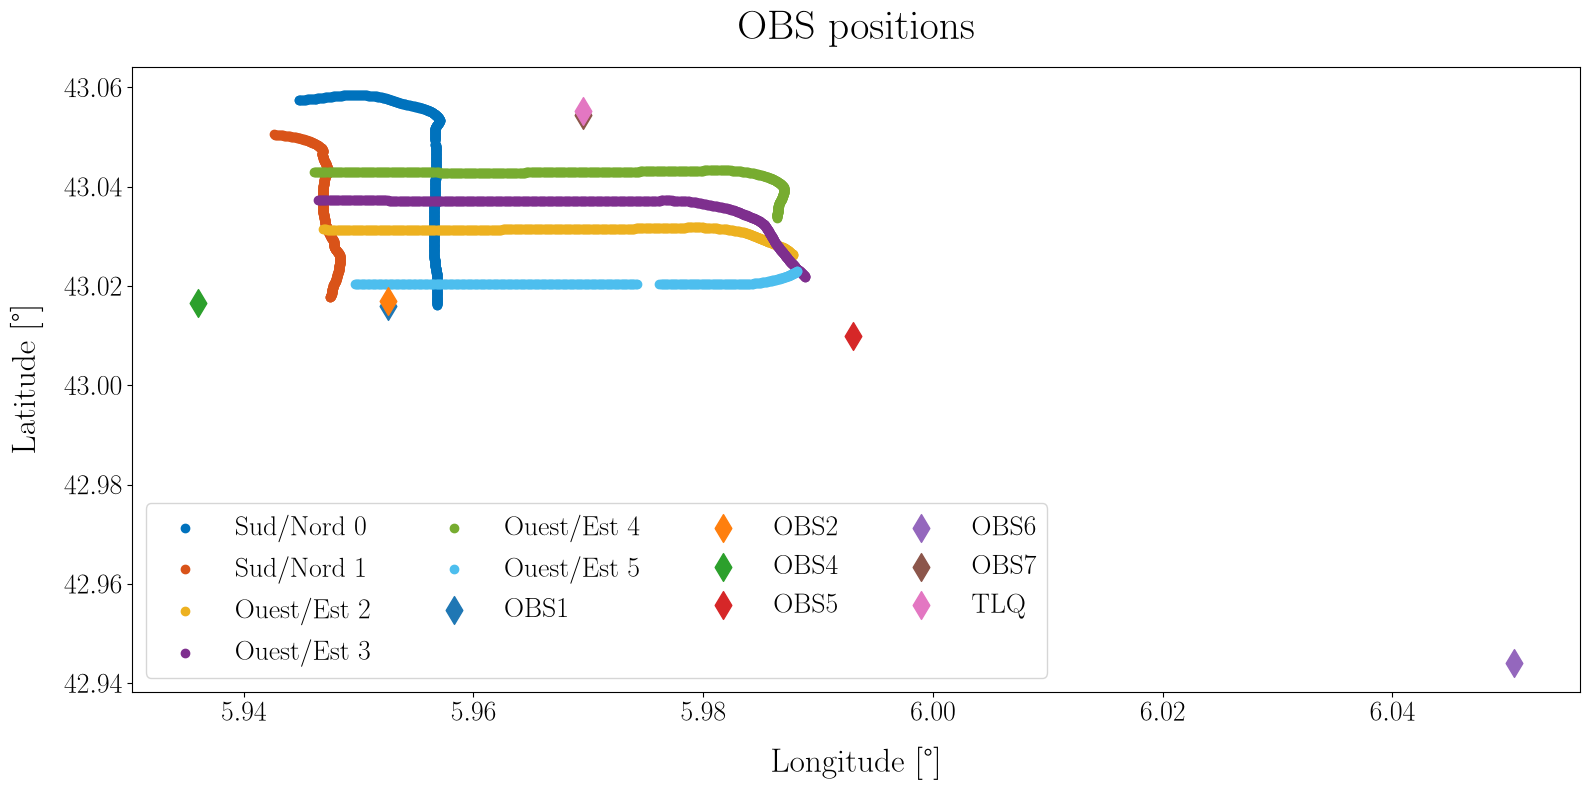

In [90]:
plot_portion_tir_pos(portion_tree=portion)

## Illustration du décalage observé 

In [91]:
c0 = 1508       # equivalent celerity 
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s
    ds_pos_section.tps_propagation_s.attrs = {
        "units": "s",
        "long_name": "Propagation time",
    }

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

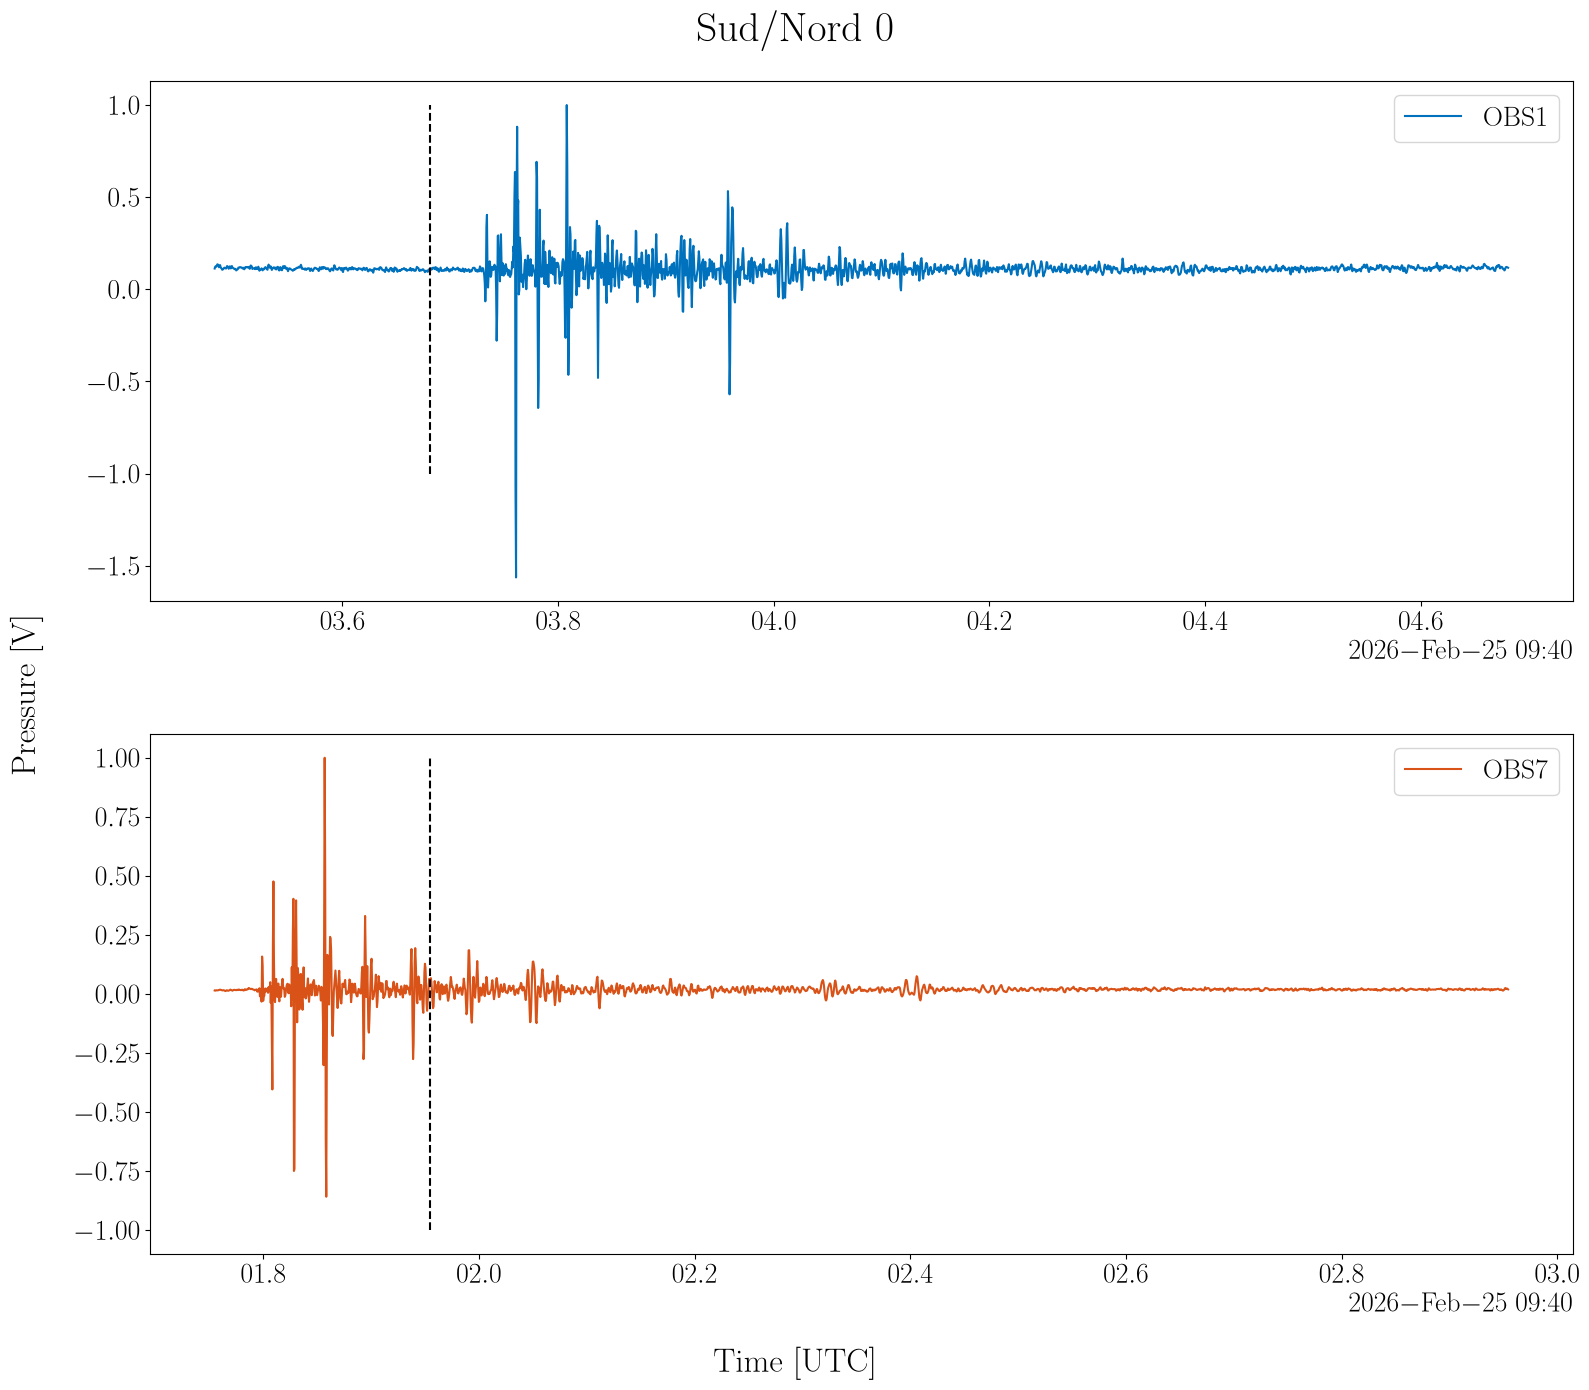

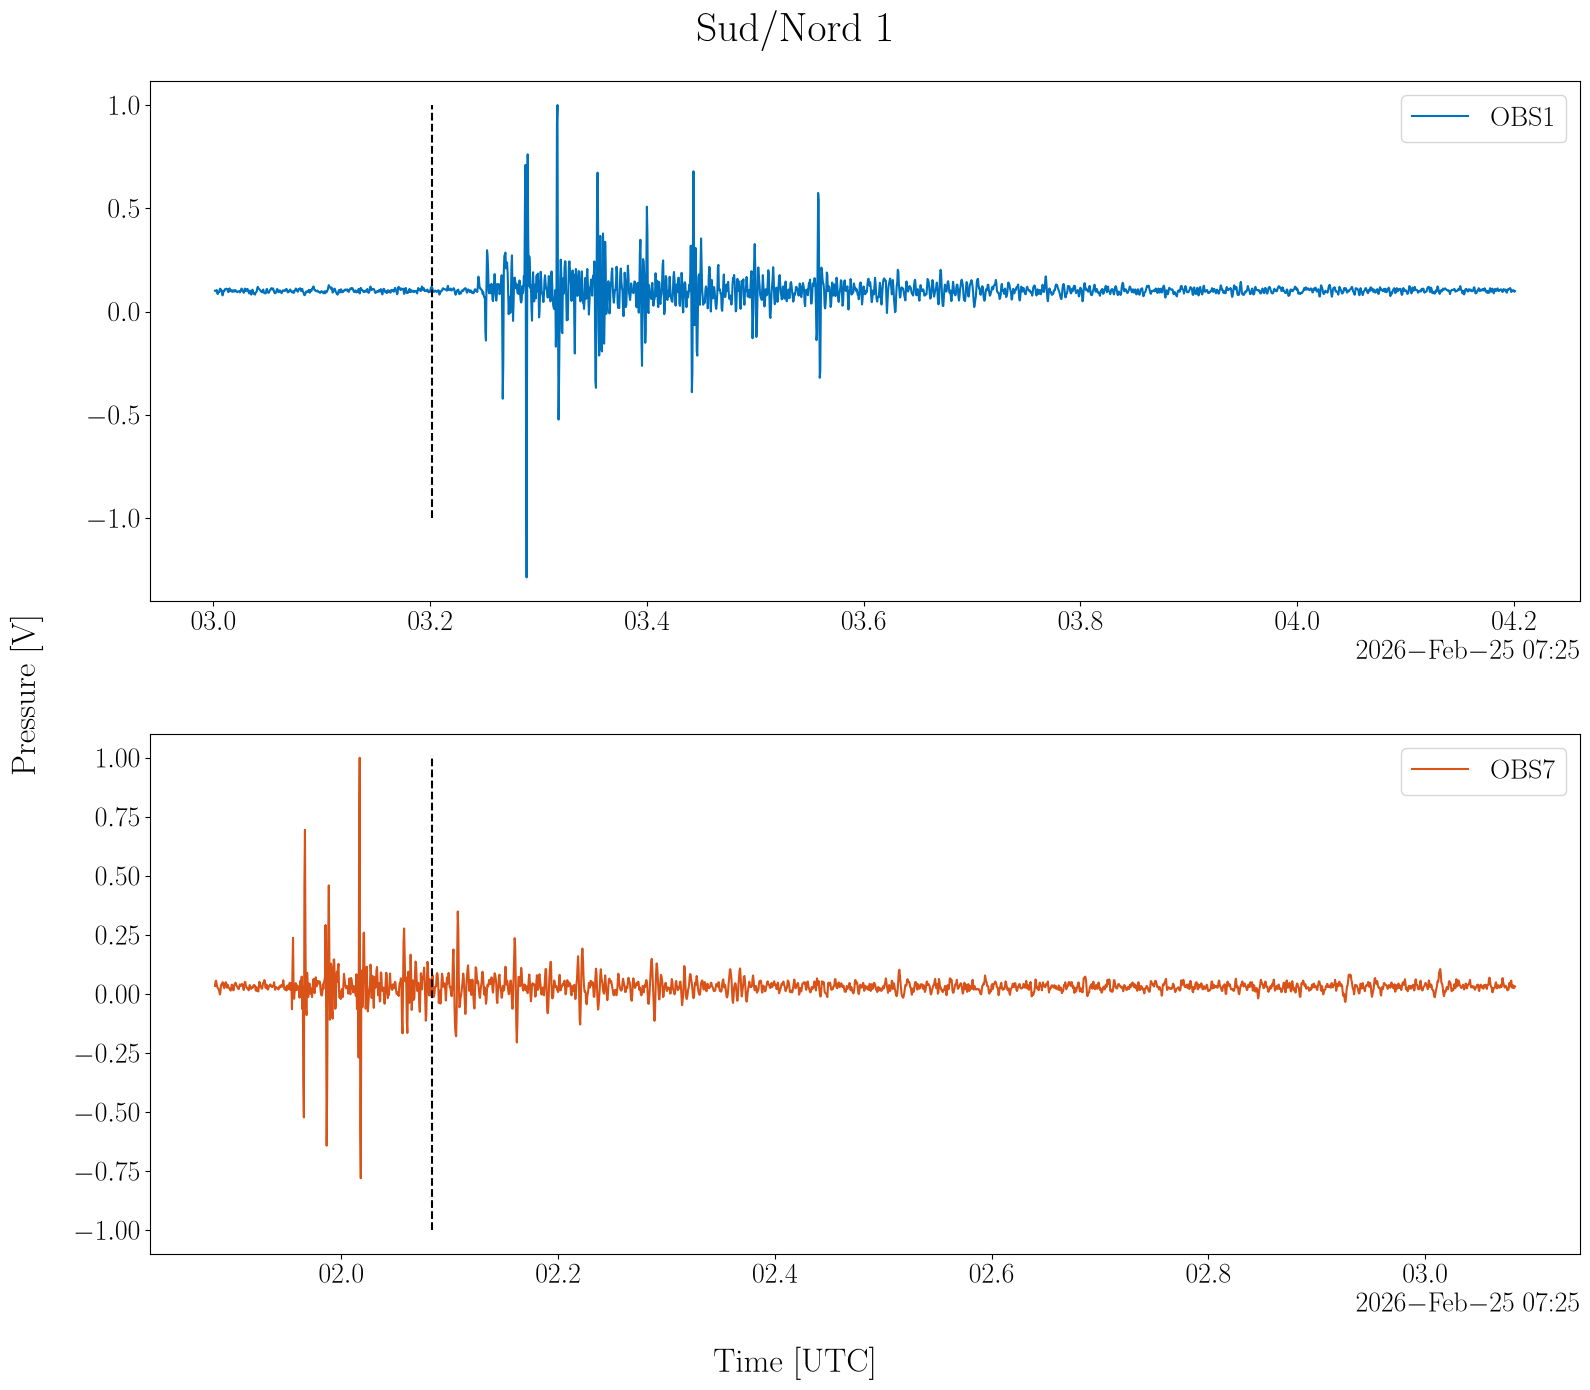

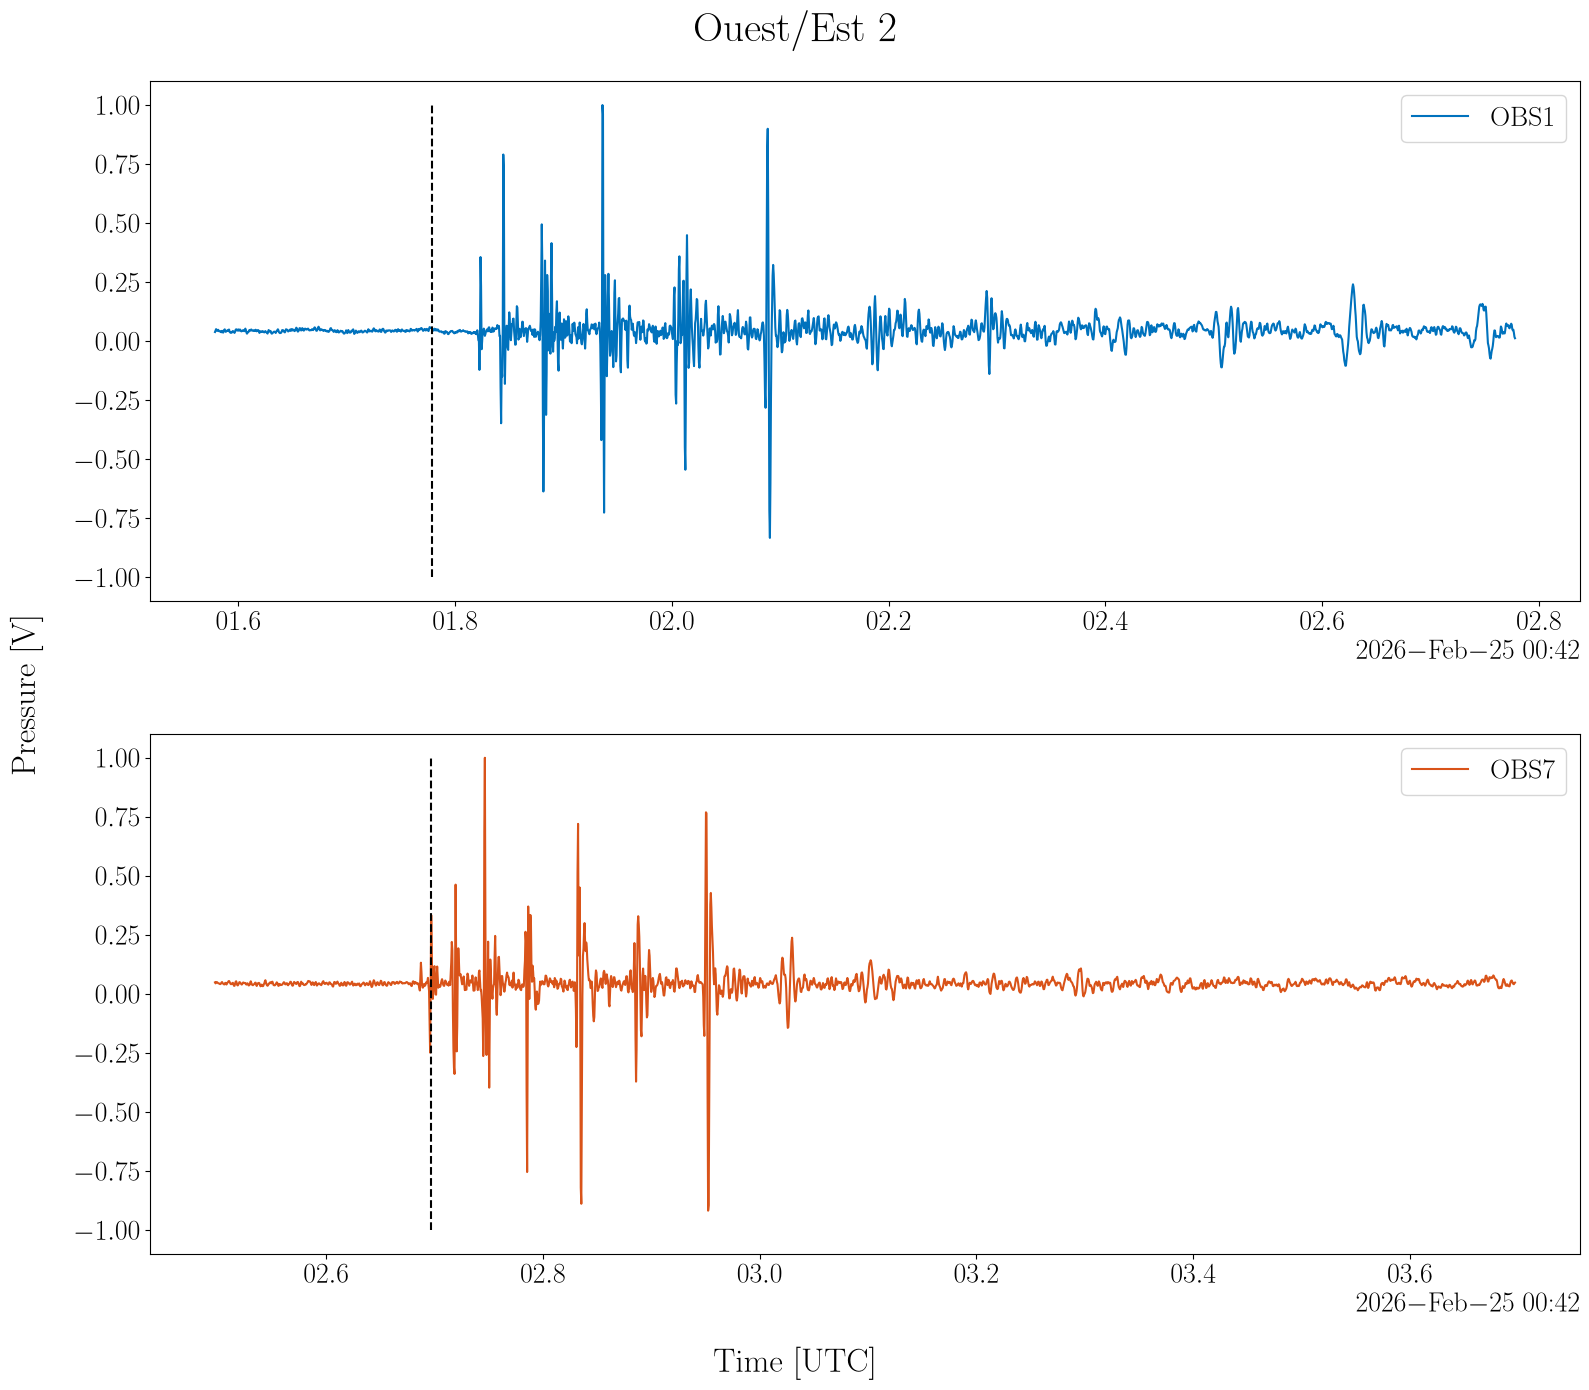

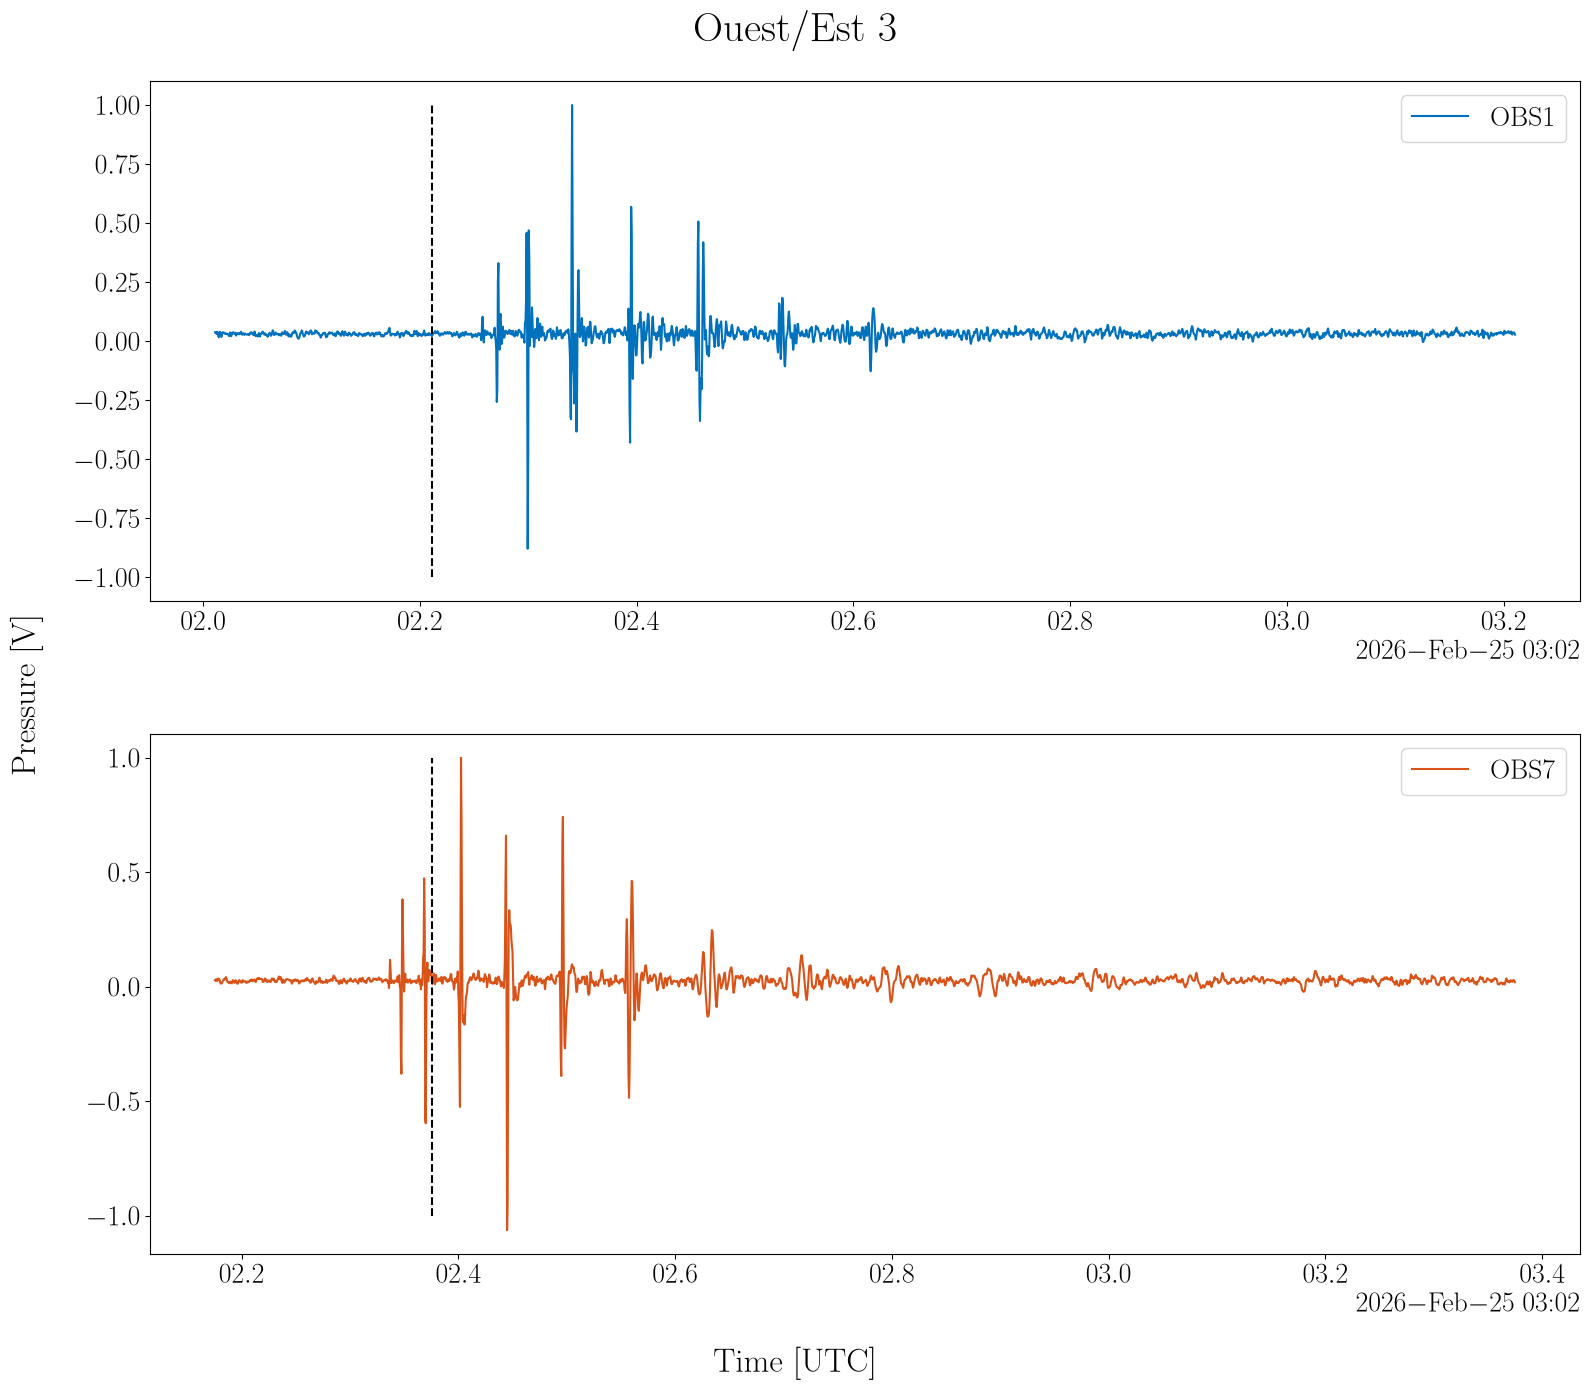

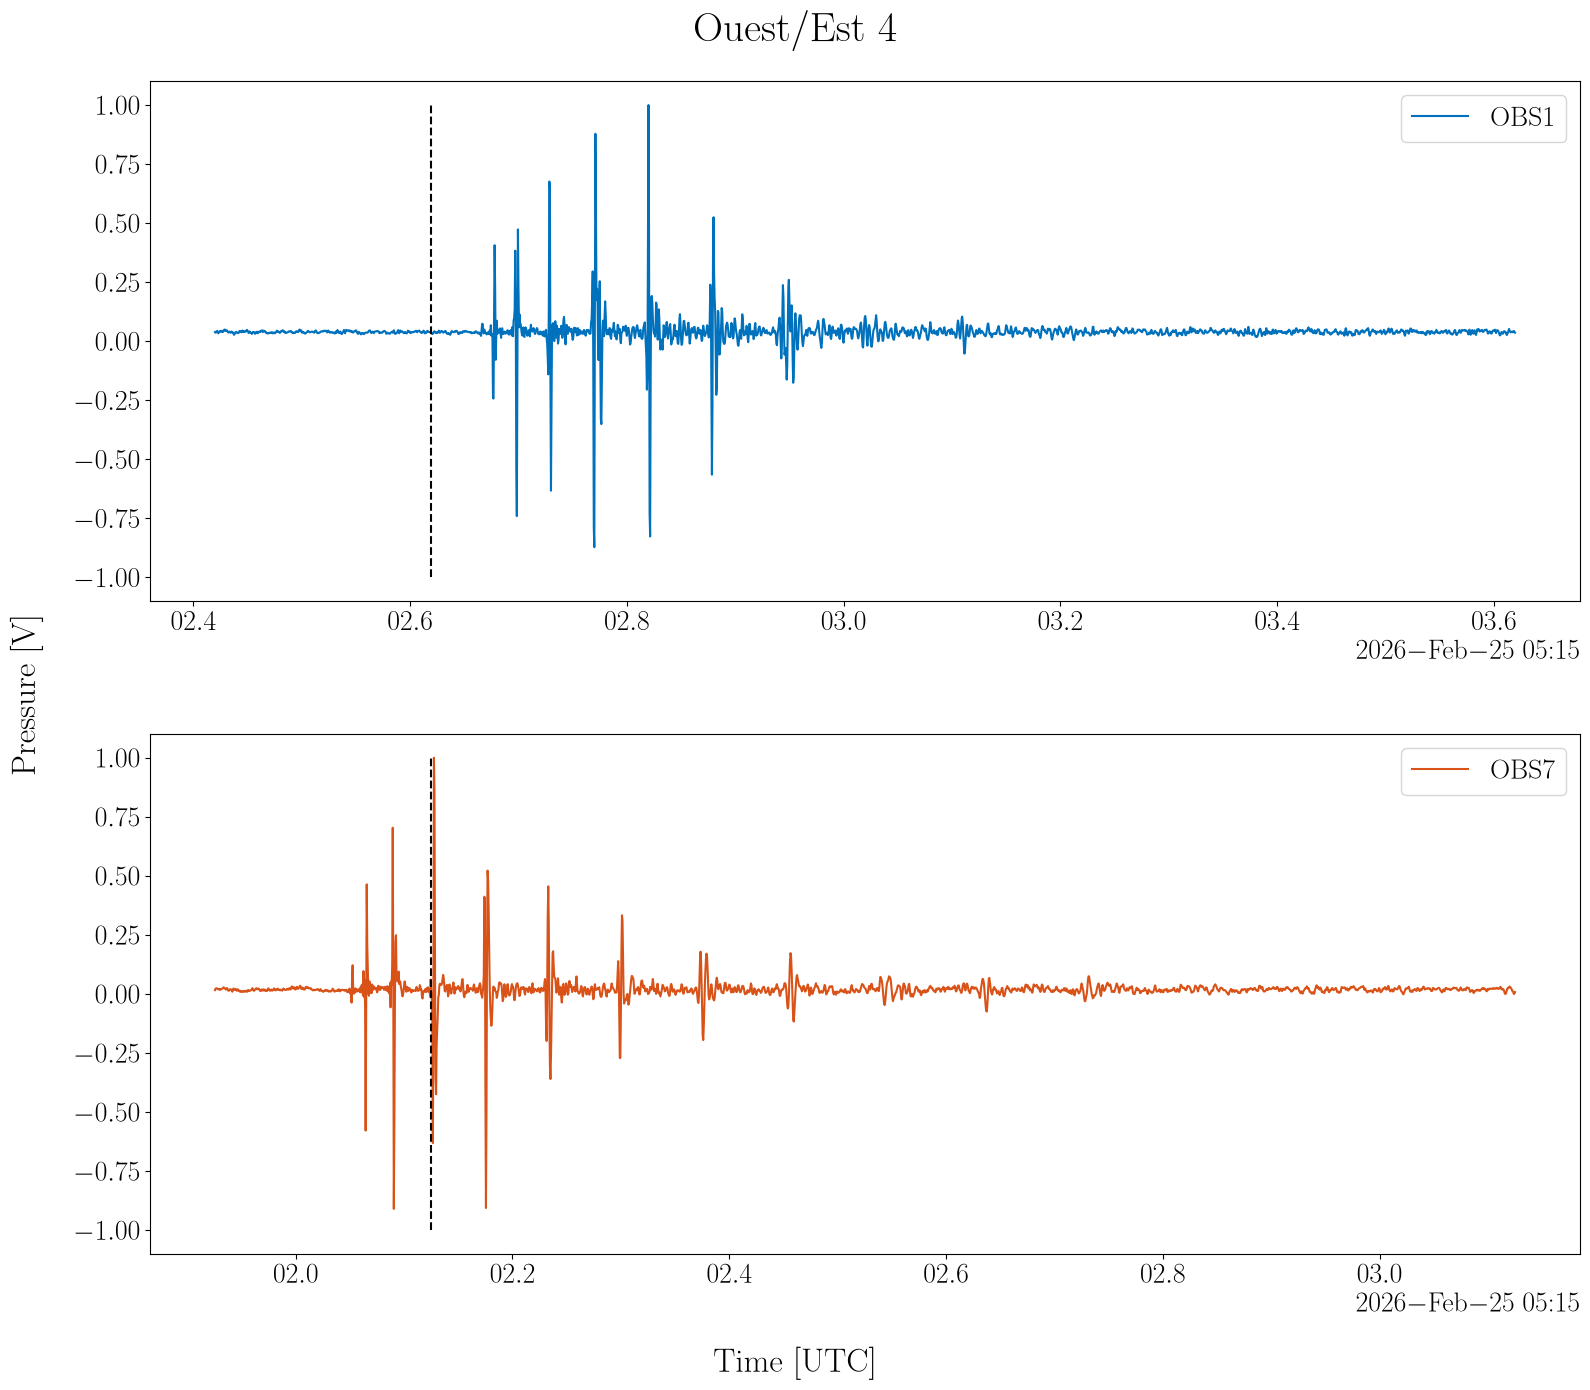

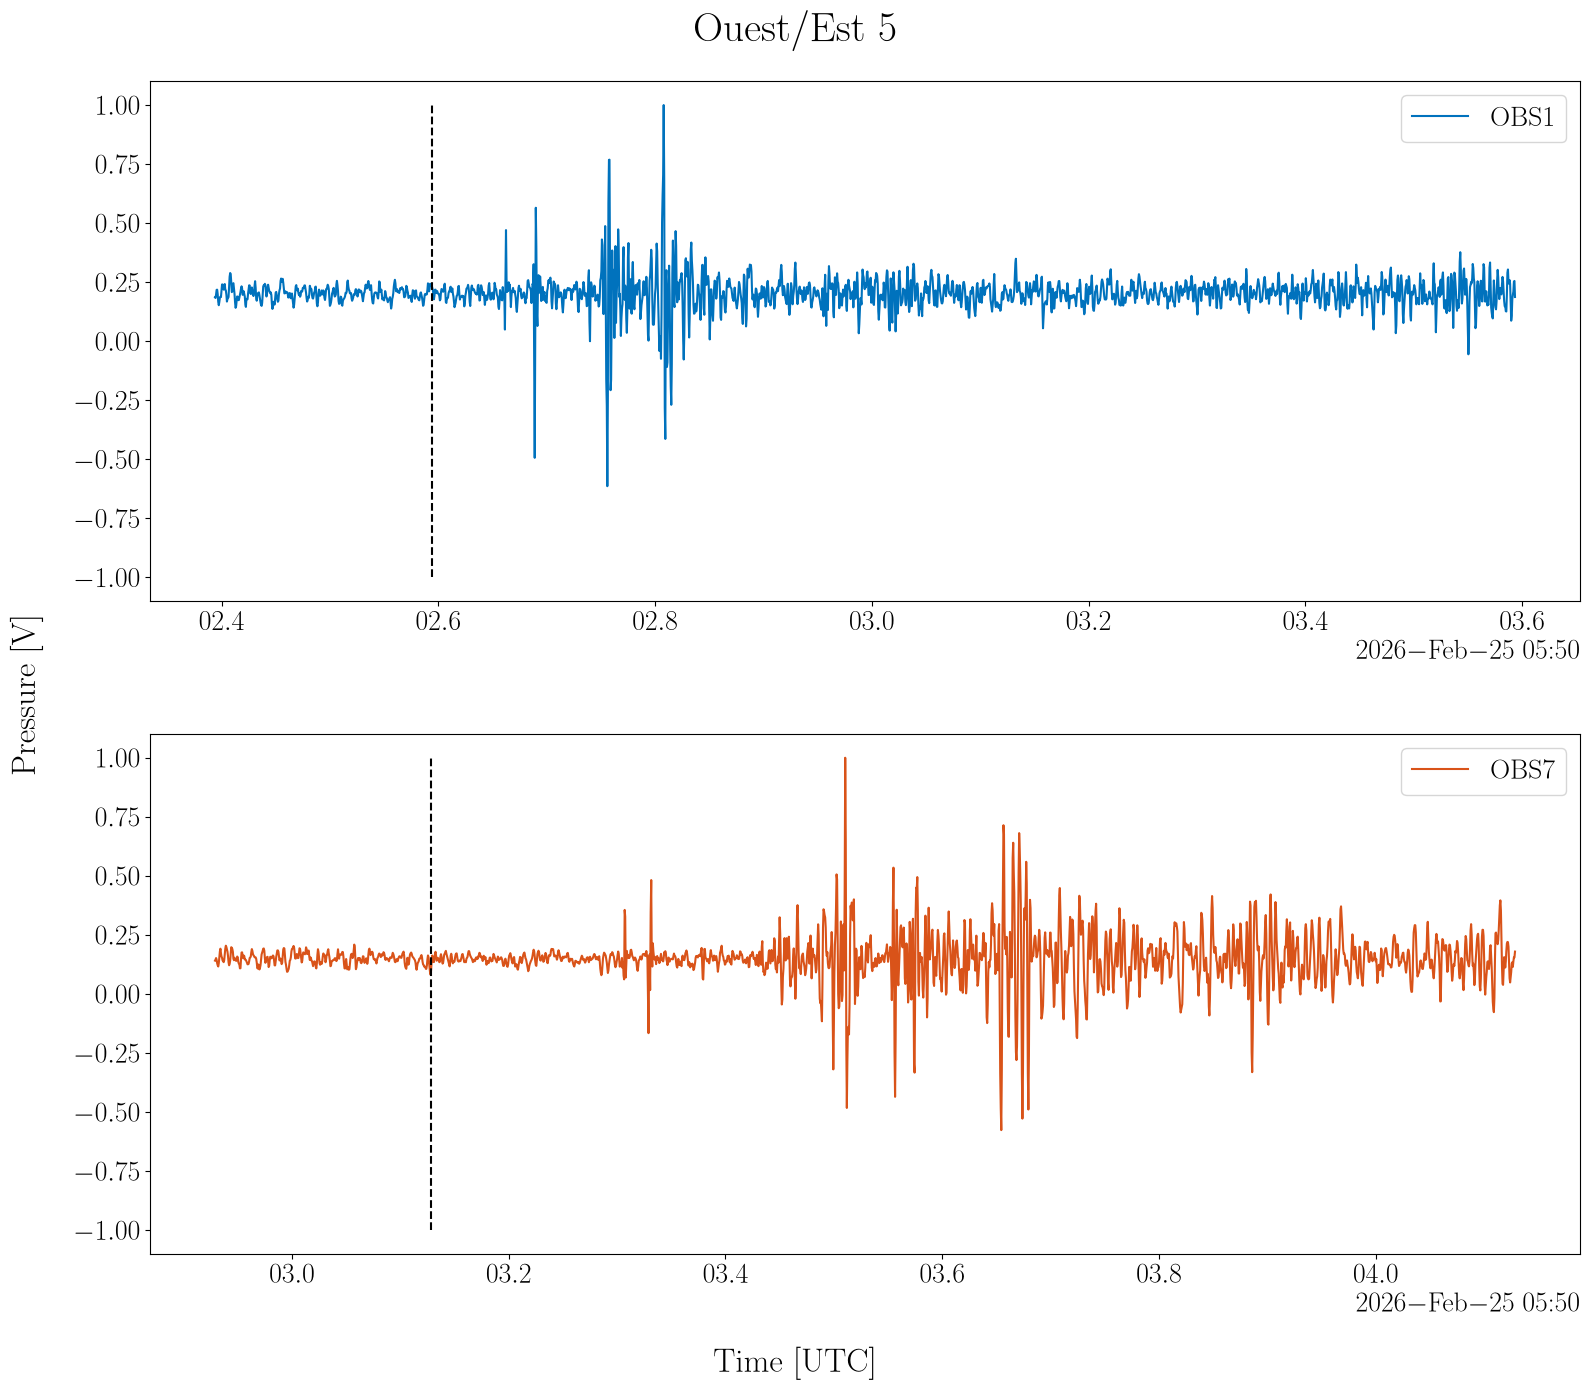

In [92]:
nb_tir = 1
offset1 = 200
offset2 = 1000
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
obs_ids = obs_ids[[0, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

Deux choses sont remarquables : 

* Le décalage observé dépend de la position de la source 
* Cette dépendance n'est a priori pas quelconque : les décalages peuvent être ordonnés, plus la source est au nord plus le décalage observé est grand. 

Ce deuxième point laisse imaginer que le vecteur d'erreur de position (vecteur entre la position estimée de l'OBS 7 et sa vraie position) est plutôt colinéaire avec les vecteurs SN0OBS7 et OE3OBS7 conduisant à une erreur de temps de propagation plus importante et plutôt orthogonal aux vecteurs OE2OBS7 et OE1OBS7 conduisant à une erreur de plus en plus faible. 

Ceci coïnciderait donc avec un vecteur de repositionnement diriger dans la direction Ouest/ Nord-Ouest. 

# Inversion de la position des OBS à partir des positions des tirs sismiques 

L'hypothèse la plus plausible à ce stade pour expliquer le décalage observée entre le temps d'arrivée théorique et le temps d'arrivée observé pour l'OBS 7. 

Pour tester cette hypothèse on peut inverser la position des OBS et en particulier de l'OBS 7 par moindres carrés. 

## Projection des coordonnées WGS84 dans un repère locale 
Afin d'appliquer la méthode des moindres carrés il est nécessaire de projeter les coordonnées dans un repère local ENU. 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

In [93]:
from source.utils.utils_geo import geodetic_to_ecef, ecef_to_enu

### Définition de l'origine du repère 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

In [94]:
def get_portion_tir_mean_pos(portion_tree):
    mean_lon = []
    mean_lat = []
    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        mean_lon.append(ds_pos_section.tir_src_lon.mean().values)
        mean_lat.append(ds_pos_section.tir_src_lat.mean().values)

    return np.mean(mean_lon), np.mean(mean_lat)

In [95]:
mean_lon, mean_lat = get_portion_tir_mean_pos(portion_tree=portion)
local_frame_origin = {"lon": mean_lon, "lat": mean_lat, "h": 0}  # MSL
local_frame_origin

{'lon': np.float64(5.963795221340651),
 'lat': np.float64(43.033776553555164),
 'h': 0}

### Ondulation du géoide 

Afin de définir convenablement l'origine du repère local ENU utilisé ainsi que la hauteur ellipsoïdale associée à chacune des positions GPS (et donc la composante z de la position de la source dans le repère ENU), il est nécessaire de connaitre l'élévation du géoïde (qui coïncide avec le niveau moyen de la mer) au-dessus de l'ellipsoïde de référence. 

Quelques définitions / notations : 

* H : altitude orthométrique (altitude au-dessus du géoïde)
* h : altitude géographique (hauteur au-dessus de l'ellipsoïde de référence WGS84), c'est l'altitude donnée par le positionnement GPS standard. 
* N : ondulation du géoïde (hauteur du géoïde au-dessus de l'ellipsoïde de référence)

Ces trois grandeurs sont reliées par la relation suivante : 

$$
h \approx H + N 
$$

L'approximation est valide au niveau millimétrique. 

Afin d'accéder à l'ondulation du géoïde N dans la zone d'intérêt il est nécessaire d'utiliser un modèle global du champ de pesanteur terrestre. Le modèle couramment utilisé est le modèle EGM2008. L'EGM2008 (Earth Gravitational Model EGM2008) est un modèle global du champ de pesanteur
terrestre diffusé sous la forme d’harmoniques sphériques développés jusqu’à l’ordre 2159 (Pavlis et al., 2012). Il est issu de données de gravimétrie terrestres, aéroportées et spatiales.

En python, il semble que l'on puisse accéder à une estimation de l'ondulation du géoïde à l'aide de la librairie geoid_toolkit. Cependant, la fonction geoid_undulation(lat, lon, "WGS84", clm, slm, lmax, R, GM) nécessite de fournir les paramètres du développement en harmoniques sphériques. Par soucis de simplicité, et au vu des incertitudes sur le reste des coordonnées verticales que l'on manipule ici, on se contente ici d'une valeur fournie par le site web https://geographiclib.sourceforge.io/cgi-bin/GeoidEval?input=47.5+-3.5&option=Submit pour la position de référence (origine du repère local). 

$$
lon_0 = 5.946085^\circ, lat_0 = 43.042972^\circ
$$
 
$$
N(lon_0, lat_0) = 48.5778 ~\text{m (EGM2008)} 
$$

In [96]:
N_geoid_undulation = 48.5

In [97]:
def transform_pos_wgs84_enu(
    lon, lat, local_frame_origin, N_geoid_undulation, zeta=0, sensor_h_above_sea_level=5
):
    lon = np.deg2rad(lon)
    lat = np.deg2rad(lat)
    # GPS h above WGS84 ellipsoid
    h = N_geoid_undulation + zeta + sensor_h_above_sea_level
    # WGS84 -> ECEF
    x, y, z = geodetic_to_ecef(lat, lon, h)
    # ECEF -> ENU
    lat0, lon0, h0 = (
        np.deg2rad(local_frame_origin["lat"]),
        np.deg2rad(local_frame_origin["lon"]),
        local_frame_origin["h"],
    )
    e, n, u = ecef_to_enu(x, y, z, lat0, lon0, h0)

    return e, n, u

### Projection des positions des tirs sismiques 

In [98]:
def get_enu_tir_pos(portion_tree):

    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        # Convert source position from WGS84 to ecef
        tir_src_e, tir_src_n, tir_src_u = transform_pos_wgs84_enu(
            lon=ds_pos_section.tir_src_lon,
            lat=ds_pos_section.tir_src_lat,
            local_frame_origin=local_frame_origin,
            N_geoid_undulation=N_geoid_undulation,
            zeta=0,
            sensor_h_above_sea_level=-5,  # Source is approximately 5 meter below sea surface = MSL
        )
        # Add to portion
        ds_pos_section["tir_src_e"] = (["src_datetime"], tir_src_e)
        ds_pos_section["tir_src_n"] = (["src_datetime"], tir_src_n)
        ds_pos_section["tir_src_u"] = (["src_datetime"], tir_src_u)
        # Update attribute
        ds_pos_section.tir_src_e.attrs = {
            "units": "m",
            "long_name": "E",
        }
        ds_pos_section.tir_src_n.attrs = {
            "units": "m",
            "long_name": "N",
        }
        ds_pos_section.tir_src_u.attrs = {
            "units": "m",
            "long_name": "U",
        }

        # Update tree
        node.ds = ds_pos_section

In [99]:
get_enu_tir_pos(portion_tree=portion)

In [100]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1970, mmsi: 526,
│   │                                    ais_datetime: 211, src_datetime: 690)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 16kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:4...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/19)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 16kB ...
│   │           atl_lat                 (atl_datetime) float64 16kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 888kB ...
│   │           ...                      ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 39kB 4.645e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 39kB 3.081 ... 2.965
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 39kB 2026-0...
│   │           tir_src_e               (src_datetime) float64 6kB -1.55e+03 ... -568.2
│   │           tir_src_n               (src_datetime) float64 6kB 2.626e+03 ... -1.959e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.77 42.77 ... 43.17
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               3
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1473, mmsi: 526,
│   │                                    ais_datetime: 151, src_datetime: 488)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 12kB 2026-02-25T07:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 1kB 2026-02-25T07:2...
│   │         * src_datetime            (src_datetime) datetime64[ns] 4kB 2026-02-25T07:2...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/19)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 12kB ...
│   │           atl_lat                 (atl_datetime) float64 12kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 635kB ...
│   │           ...                      ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 27kB 3.921e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 27kB 2.601 ... 3.013
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 27kB 2026-0...
│   │           tir_src_e               (src_datetime) float64 4kB -1.726e+03 ... -1.328e+03
│   │           tir_src_n               (src_datetime) float64 4kB 1.861e+03 ... -1.783e+03
│   │           tir_src_u               (src_datetime) float64 4kB 42.99 43.0 ... 43.11
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:        

### Projection des positions des OBS

In [101]:
def get_enu_rcv_pos(portion_tree):

    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        # Convert OBS position from WGS84 to ecef
        rcv_e, rcv_n, rcv_u = transform_pos_wgs84_enu(
            lon=ds_pos_section.rcv_lon,
            lat=ds_pos_section.rcv_lat,
            local_frame_origin=local_frame_origin,
            N_geoid_undulation=N_geoid_undulation,
            zeta=0,
            sensor_h_above_sea_level=-ds_pos_section.rcv_immersion,
        )
        # Add to portion
        ds_pos_section["rcv_e"] = (["rcv_id"], rcv_e)
        ds_pos_section["rcv_n"] = (["rcv_id"], rcv_n)
        ds_pos_section["rcv_u"] = (["rcv_id"], rcv_u)
        # Update attribute
        ds_pos_section.rcv_e.attrs = {
            "units": "m",
            "long_name": "E",
        }
        ds_pos_section.rcv_n.attrs = {
            "units": "m",
            "long_name": "N",
        }
        ds_pos_section.rcv_u.attrs = {
            "units": "m",
            "long_name": "U",
        }

        # Update tree
        node.ds = ds_pos_section

In [102]:
get_enu_rcv_pos(portion_tree=portion)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1970, mmsi: 526,
│   │                                    ais_datetime: 211, src_datetime: 690)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 16kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:4...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.953 5.953 5.936 ... 5.97 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.05 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 16kB ...
│   │           atl_lat                 (atl_datetime) float64 16kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 888kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 6kB -1.55e+03 ... -568.2
│   │           tir_src_n               (src_datetime) float64 6kB 2.626e+03 ... -1.959e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.77 42.77 ... 43.17
│   │           rcv_e                   (rcv_id) float64 56B -912.6 -912.6 ... 464.8 464.8
│   │           rcv_n                   (rcv_id) float64 56B -1.975e+03 ... 2.391e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.87 -67.84 ... -44.93 -44.97
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               3
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1473, mmsi: 526,
│   │                                    ais_datetime: 151, src_datetime: 488)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 12kB 2026-02-25T07:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 1kB 2026-02-25T07:2...
│   │         * src_datetime            (src_datetime) datetime64[ns] 4kB 2026-02-25T07:2...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B 5.953 5.953 5.936 ... 5.97 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.05 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 12kB ...
│   │           atl_lat                 (atl_datetime) float64 12kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 635kB ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 4kB -1.726e+03 ... -1.328e+03
│   │           tir_src_n               (src_datetime) float64 4kB 1.861e+03 ... -1.783e+03
│   │           tir_src_u               (src_datetime) float64 4kB 42.99 43.0 ... 43.11
│   │           rcv_e                   (rcv_id) float64 56B -912.6 -912.6 ... 464.8 464.8
│   │           rcv_n                   (rcv_id) float64 56B -1.975e+03 ... 2.391e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.87 -67.84 ... -44.93 -44.97
│   │       Attributes:
│   │           description:              Positions AIS int

### Comparaison des positions dans les deux repères

On s'assure que tout est ok. 

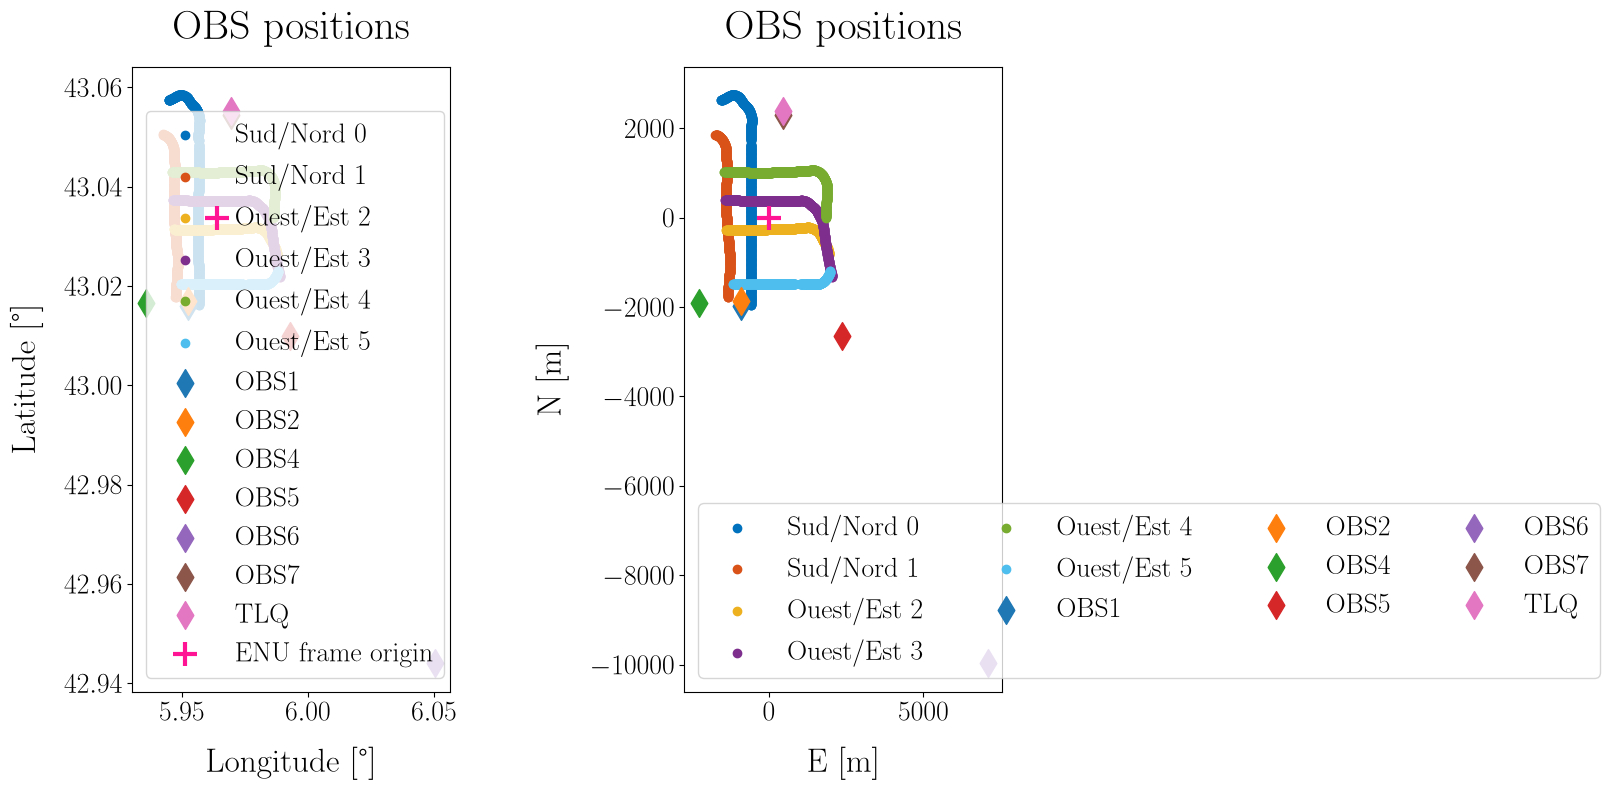

In [103]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))

# Plot pos in WGS84

plot_portion_tir_pos(portion, ax=axs[0])
# Add local frame origin position
axs[0].scatter(
    local_frame_origin["lon"],
    local_frame_origin["lat"],
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
axs[0].legend()

# Plot pos in ENU
plot_portion_tir_pos_enu(portion, ax=axs[1])
# Add local frame origin position
axs[1].scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
axs[0].legend()

Tout est ok, pas de déformation suite à la projection. 

### Comparaison pour la coordonnée verticale 


In [104]:
def get_vertical_dist(portion_tree, z_src=5):
    # Derive vertical distance between source and receiver
    v_dist_wgs84 = []
    v_dist_enu = []
    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        source_z_below_surface = np.ones_like(ds_pos_section.tir_src_u) * z_src
        vd_wgs84 = (
            ds_pos_section.rcv_immersion.values[:, np.newaxis] - source_z_below_surface[np.newaxis, :]
        )       # (nrcv, npos)
        v_dist_wgs84.append(vd_wgs84)
        vd_enu = (
            ds_pos_section.rcv_u.values[:, np.newaxis] - ds_pos_section.tir_src_u.values[np.newaxis, :]
        )       # (nrcv, npos)
        v_dist_enu.append(vd_enu)

    v_dist_wgs84 = np.hstack(v_dist_wgs84)
    v_dist_enu = -np.hstack(v_dist_enu)

    return v_dist_wgs84, v_dist_enu

In [105]:
v_dist_wgs84, v_dist_enu = get_vertical_dist(portion_tree=portion)

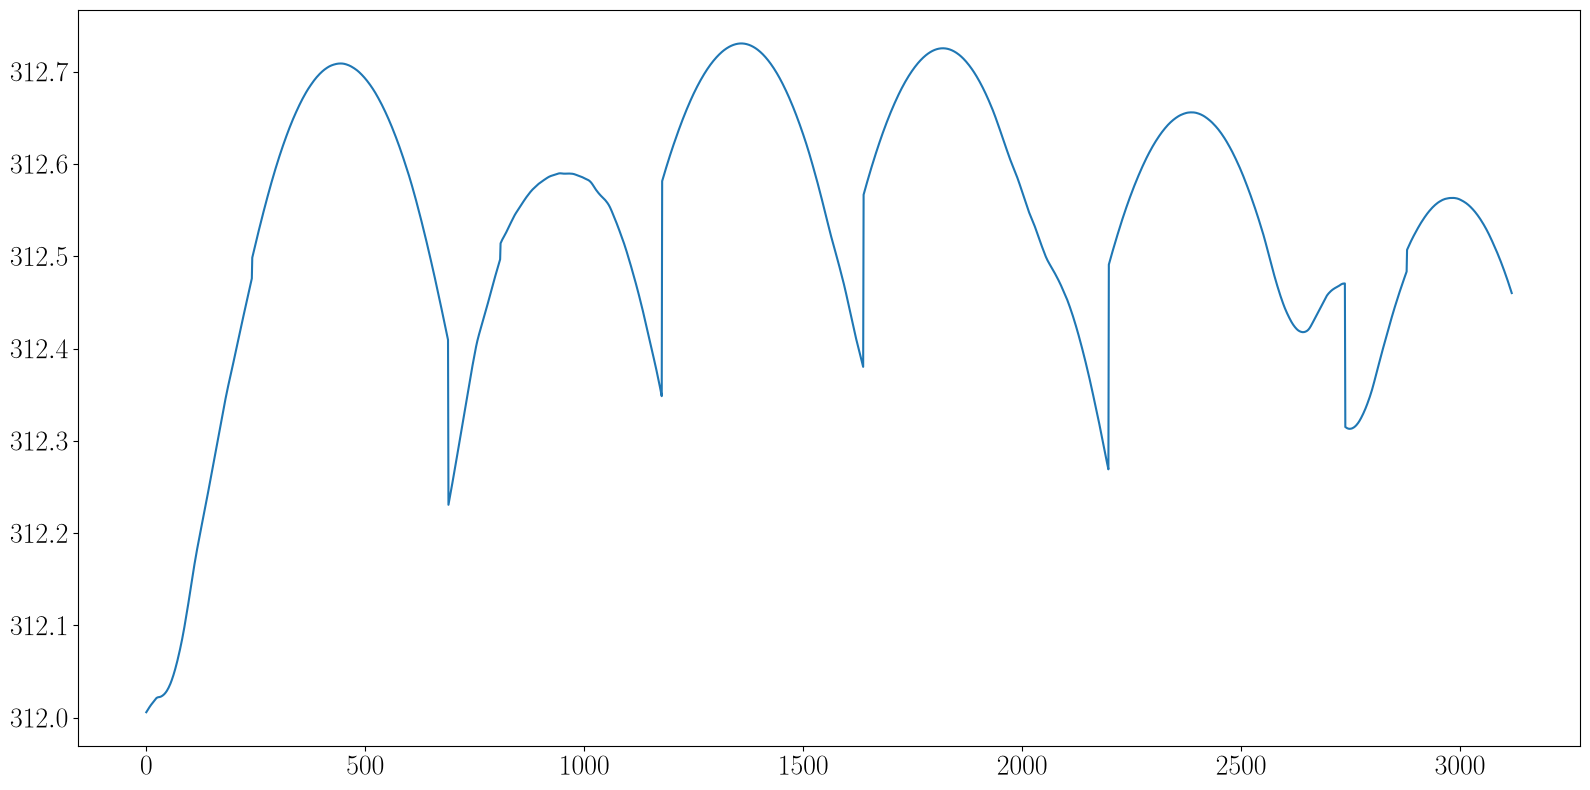

In [106]:
plt.plot(v_dist_enu[4])

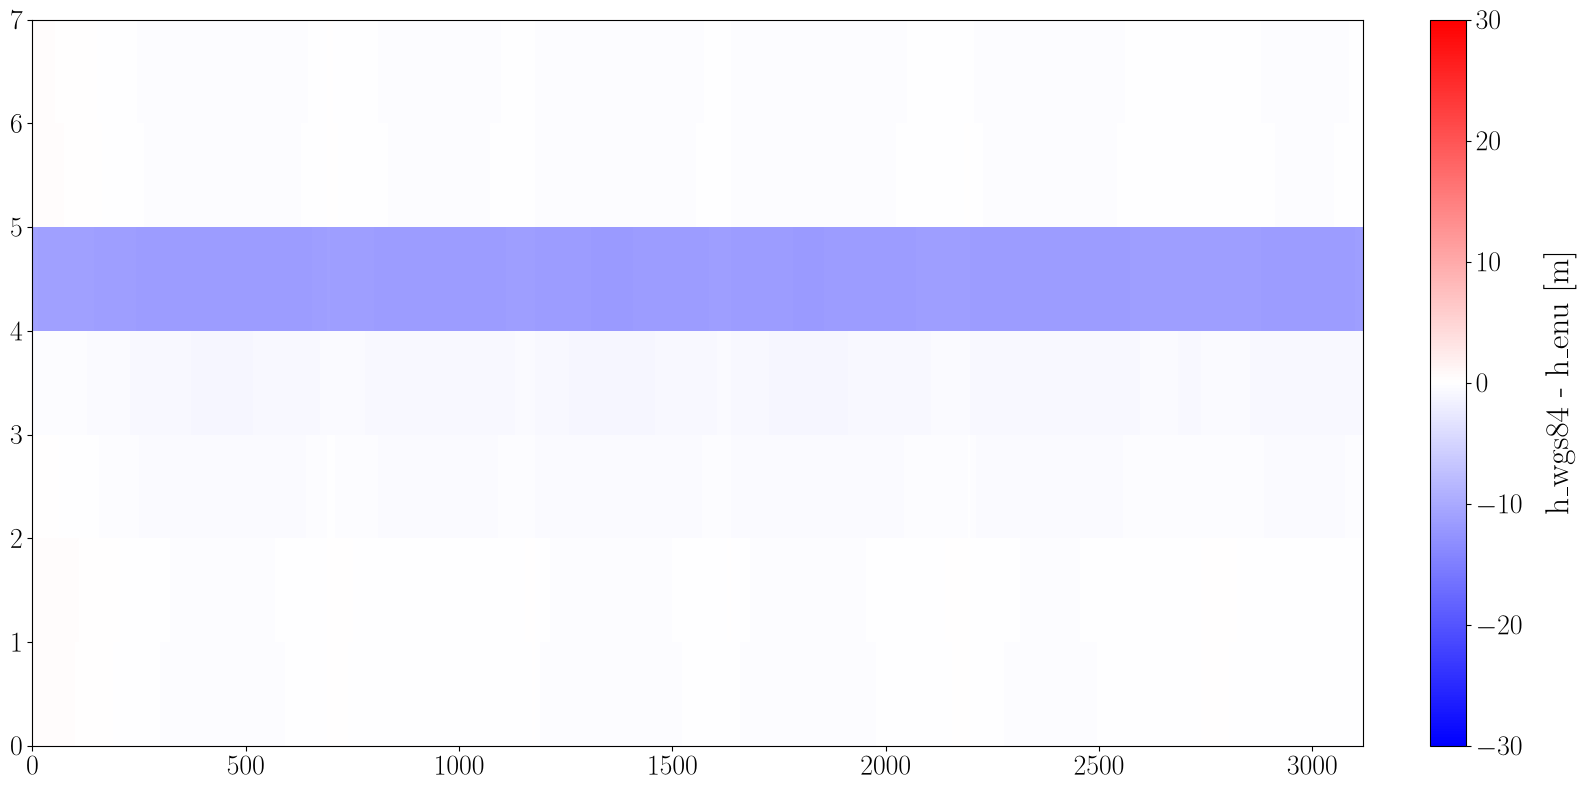

In [107]:
# fig, axs = plt.subplots(nrows=1, ncols=v_dist_enu.shape[0]-4, figsize=(16, 8))
# for i in range(v_dist_enu.shape[0]-4):
#     # Ref
#     # axs[i].plot(
#     #     [v_dist_wgs84[i, :100].min(), v_dist_wgs84[i, :100].max()],
#     #     [v_dist_enu[i, :100].min(), v_dist_enu[i, :100].max()],
#     #     color="k",
#     #     linestyle="--",
#     # )
#     # axs[i].scatter(v_dist_wgs84[i, :100], v_dist_enu[i, :100])
#     # axs[i].axis("equal")
diff_wgs84_enu = v_dist_wgs84 - v_dist_enu
im = plt.pcolormesh(diff_wgs84_enu, cmap="bwr", vmin=-30, vmax=30)
plt.colorbar(im, label="h_wgs84 - h_enu [m]")

La seule différence notable sur la coordonnée z est pour l'OBS 6 situé relativement loin (environ 13, 14 km) du centre du repère ENU. Cet écart résulte de l'écart entre le plan tangent définissant le repère ENU et la surface de l'océan courbé. 

## Estimation des temps d'arrivée 

In [108]:
import scipy.signal as sp 

### Illustration sur quelques émissions 

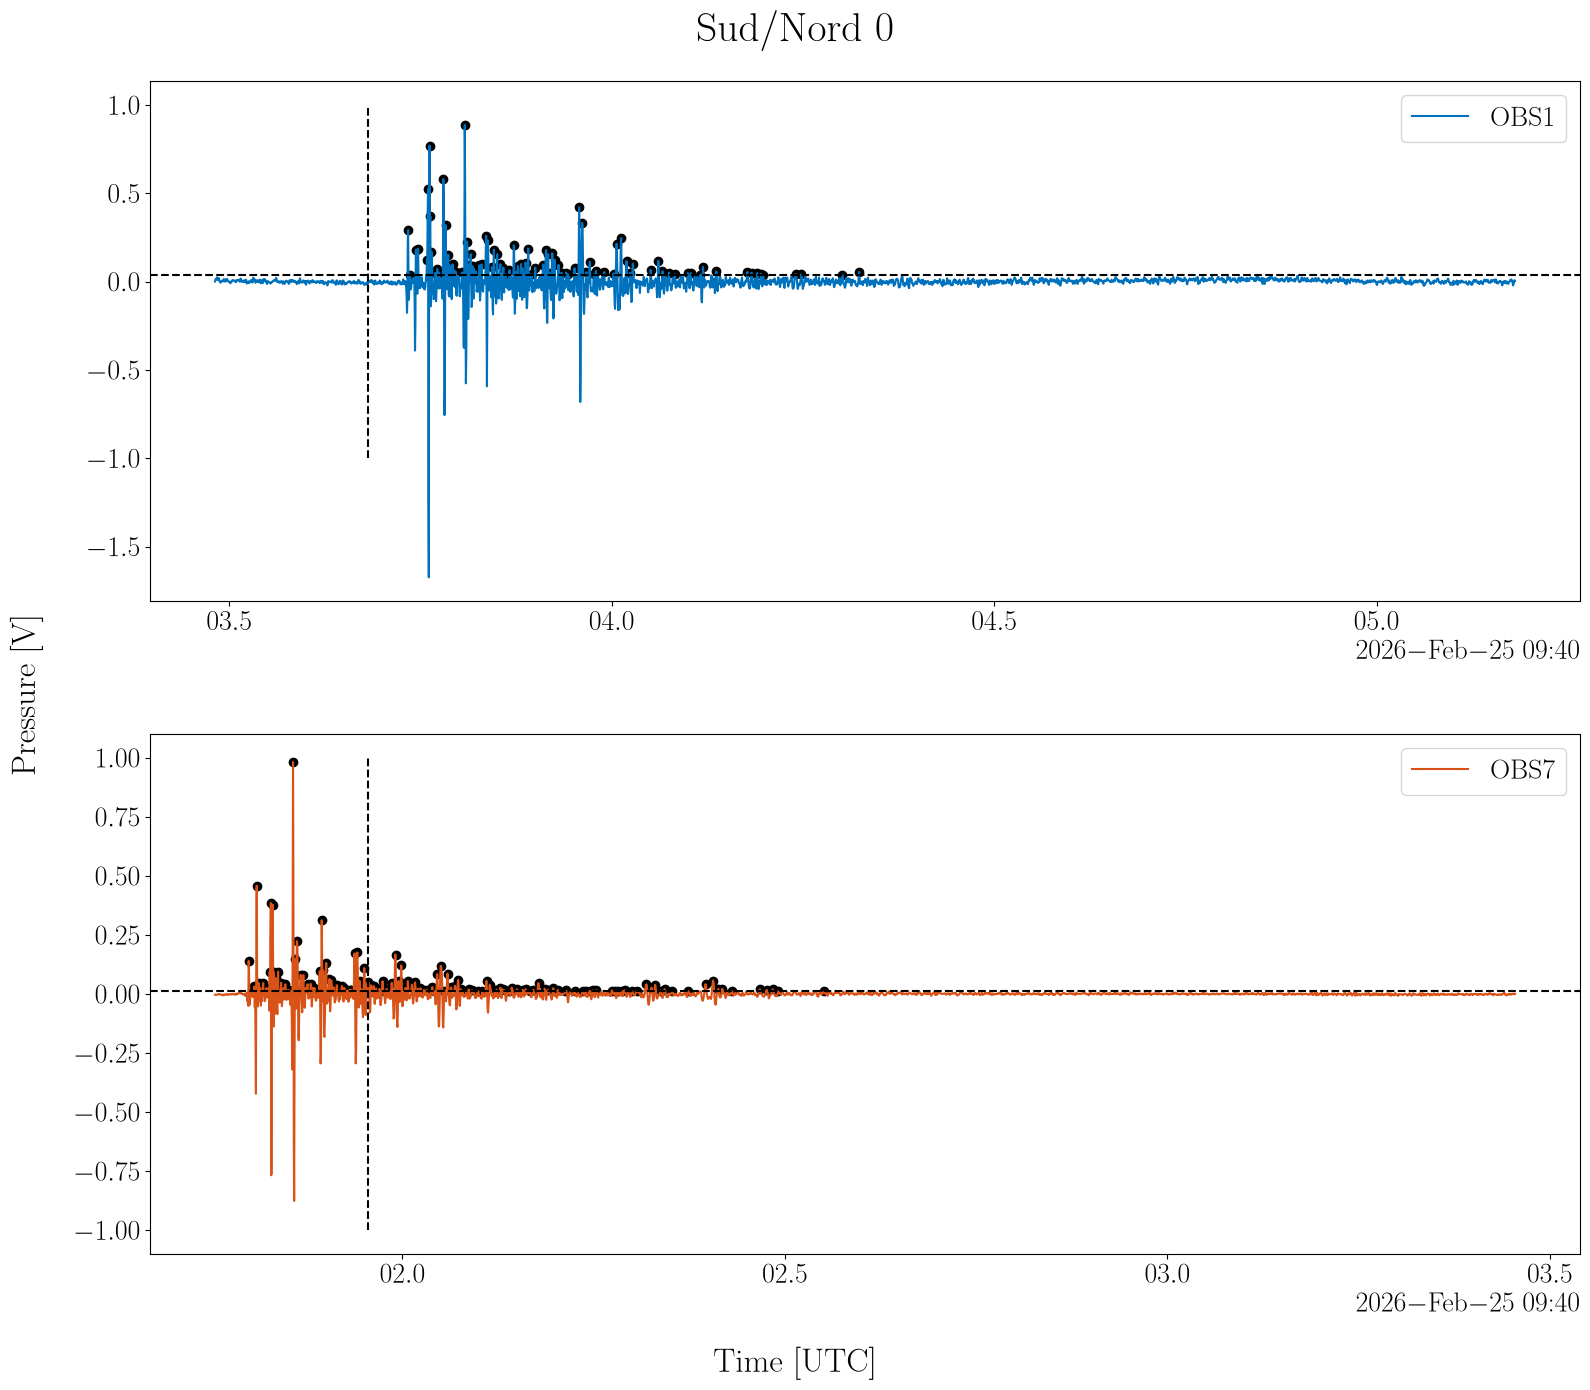

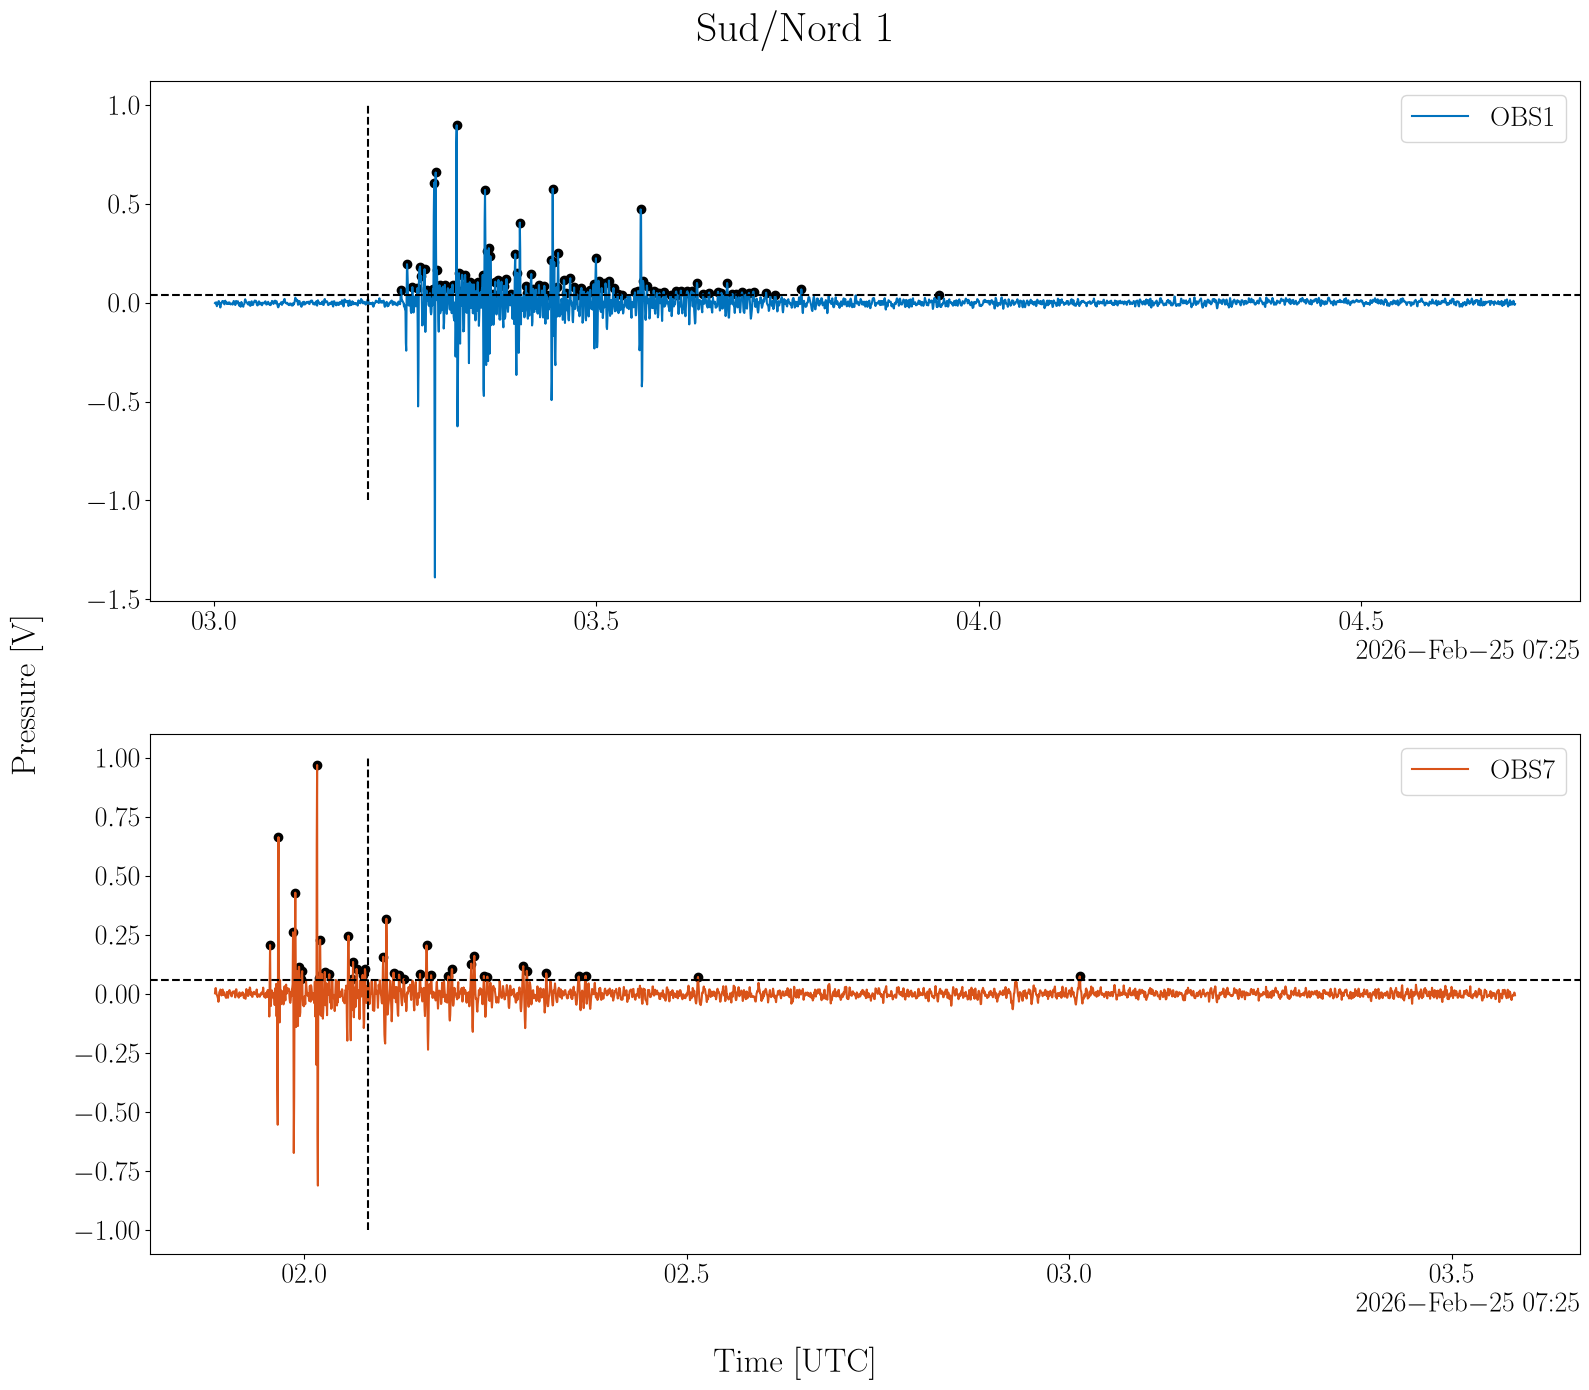

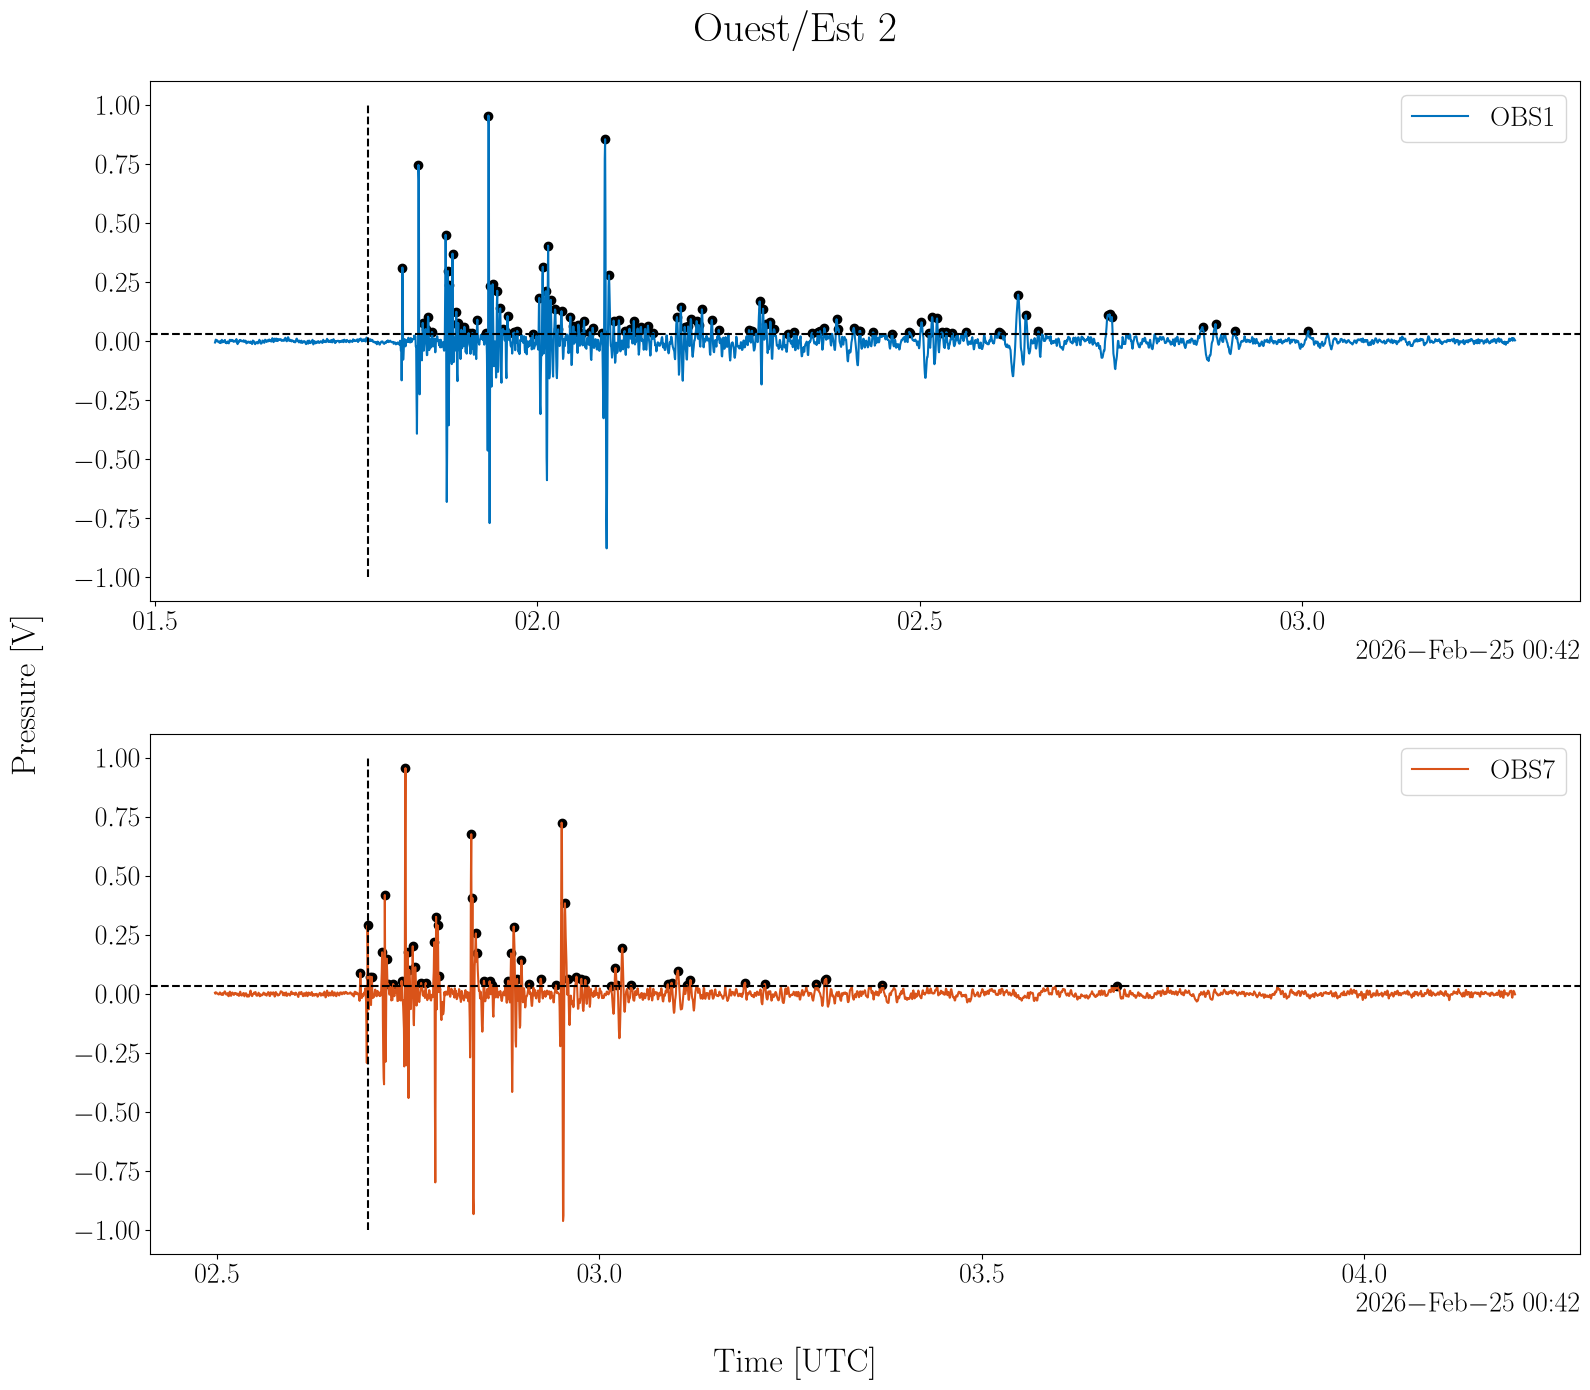

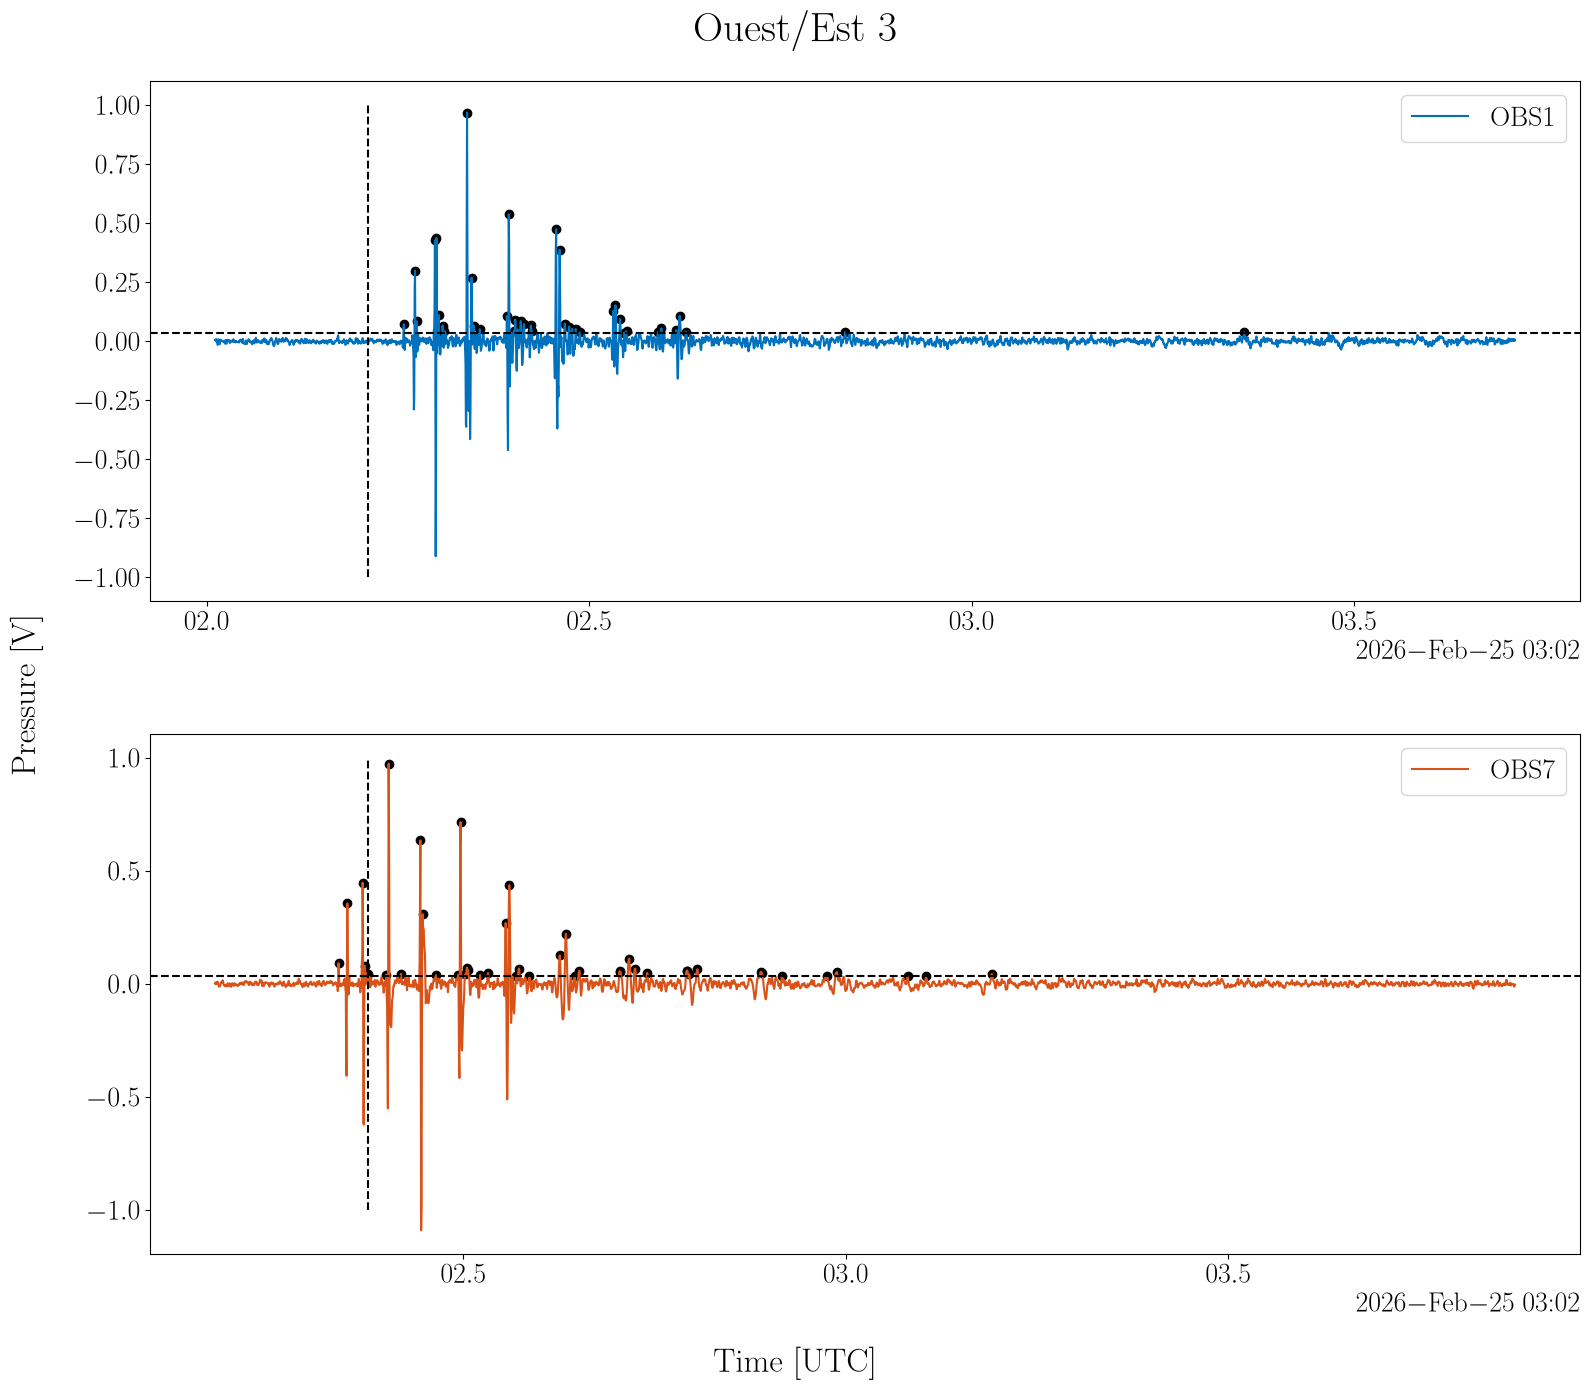

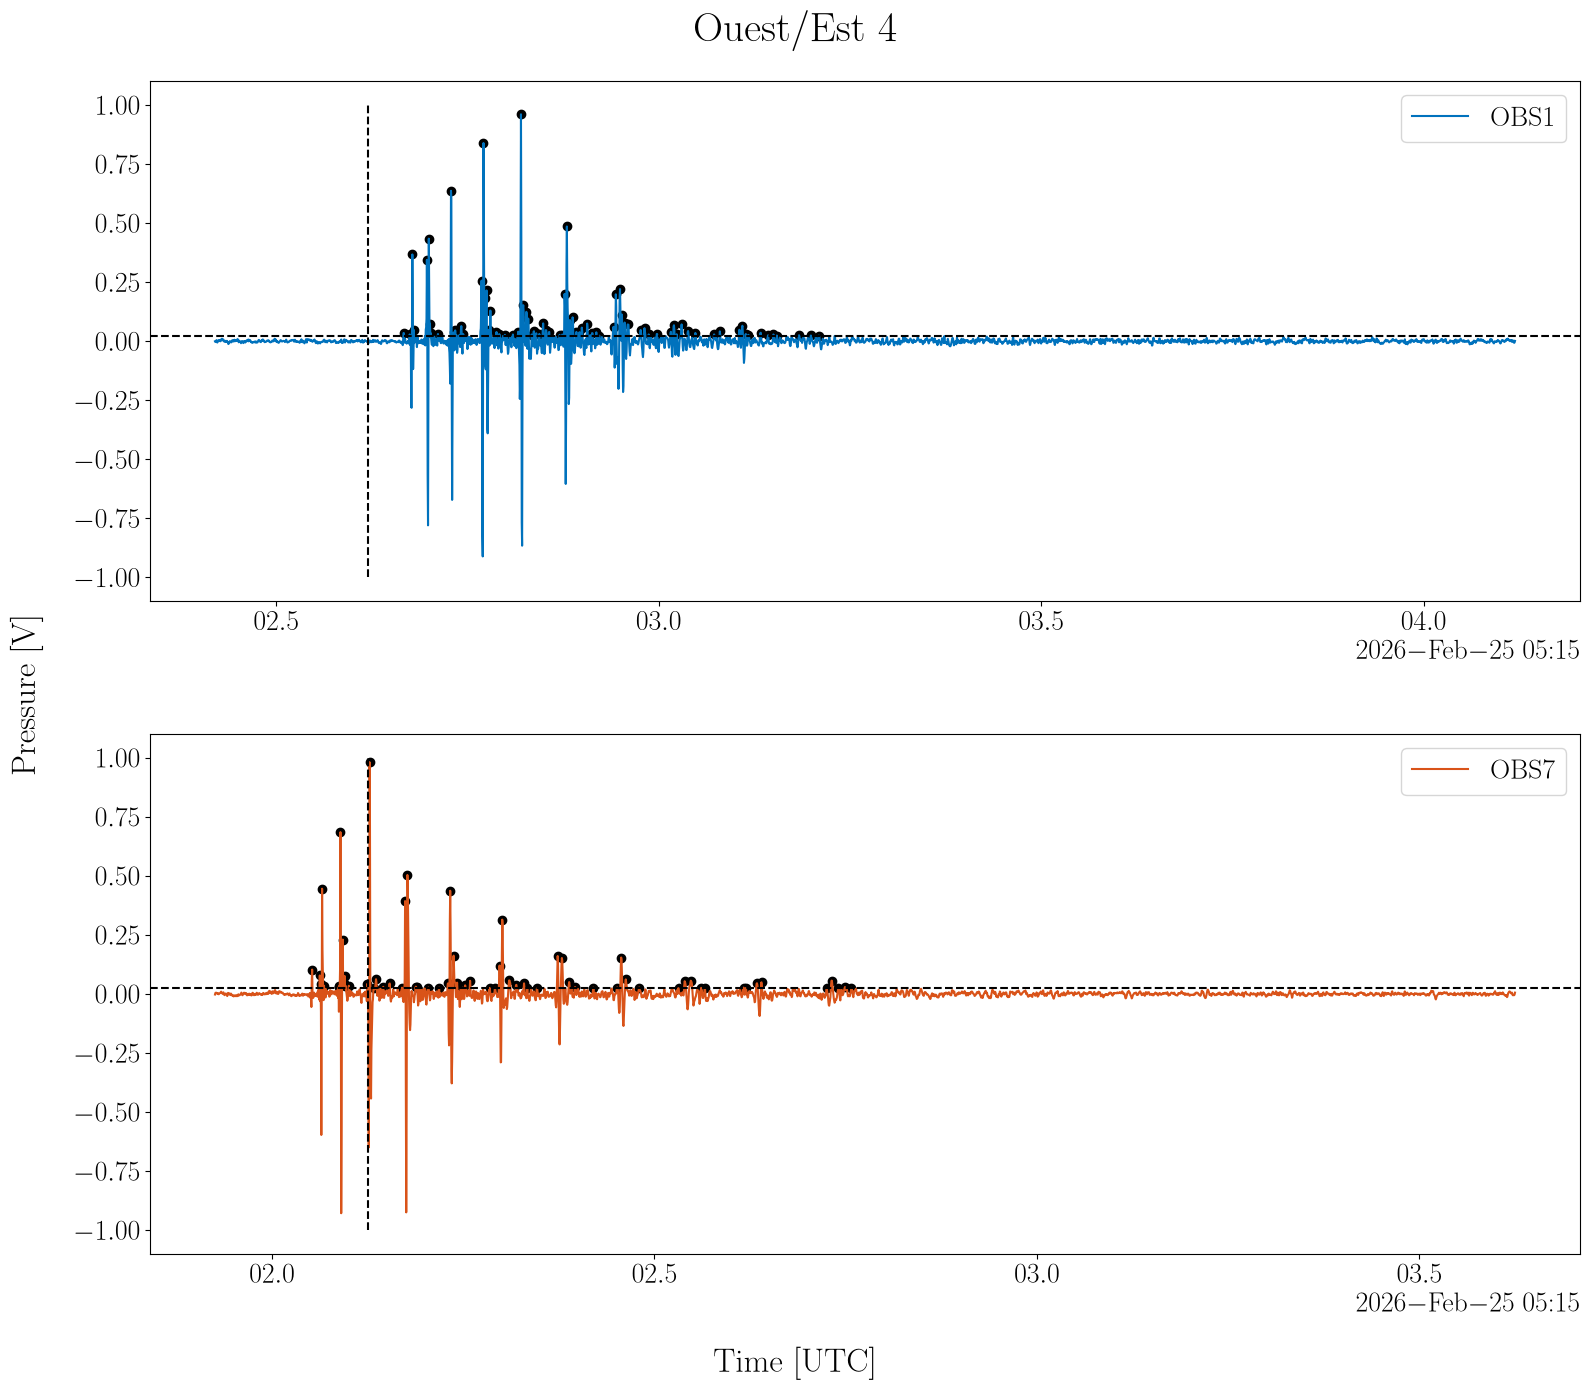

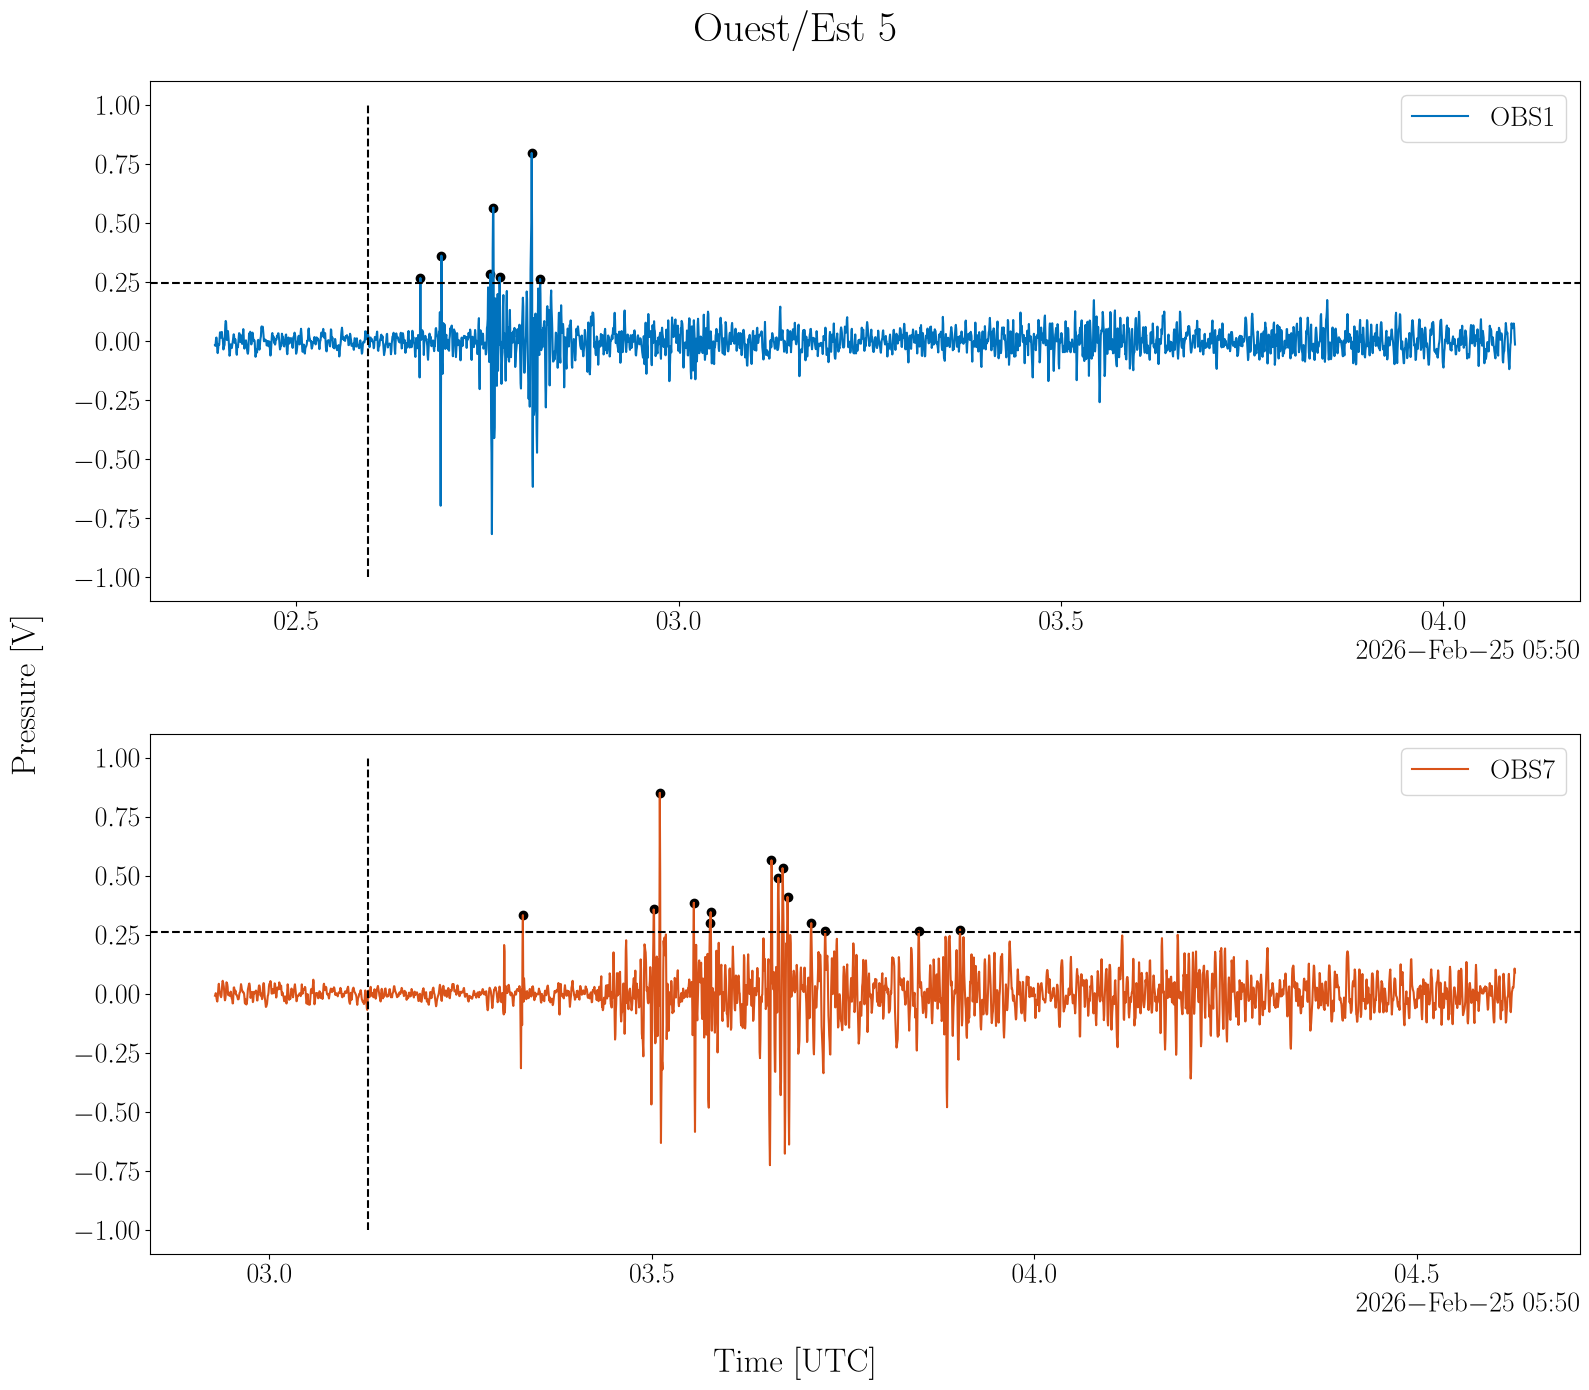

In [109]:
nb_tir = 1
offset1 = 200
offset2 = 1500
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
obs_ids = obs_ids[[0, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(
        src_datetime=slice(0, 0 + nb_tir)
    )

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
            {
                f"time_{rcv_id}": slice(
                    tir_dt_rcv.values[0] - np.timedelta64(offset1, "ms"),
                  tir_dt_rcv.values[-1] + np.timedelta64(offset2, "ms"),
                )
            }
        )
        # Plot pressure signal
        # Normalize
        press_rcv = press_rcv / press_rcv.max()
        press_rcv = press_rcv - press_rcv.mean()

        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")

        # Find peak
        peak_height = 5 * np.std(press_rcv.values[-100:])       # 5 times noise std seems like a reasonable choice 
        axs[i].axhline(peak_height, color="k", linestyle="--")
        peaks_idx, peaks_prop = sp.find_peaks(press_rcv, height=peak_height)
        # Plot peaks
        axs[i].scatter(
            press_rcv[f"time_{rcv_id}"].values[peaks_idx],
            press_rcv.values[peaks_idx],
            color="k",
        )
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(
        f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
    )
    fig.supxlabel(xlab)
    fig.supylabel(ylab)
    
    plt.show()

### Application à la portion 

In [110]:
def get_portion_tir_arr_dt(portion_tree, offset1=200, offset2=1500, obs_ids=None):
    # if obs_ids is None:
    #     obs_ids = ds_pressure_section.obs_id.values

    tps_propa_measured_s_ = []
    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        # Associated ds_pos
        ds_pressure_section = portion.pressure[name].to_dataset()

        tps_propa_measured_s = []
        # iterate over tirs
        for i_tir in range(ds_pos_section.sizes["src_datetime"]):
            # Theoretical arrival datetime
            arr_dt_th = ds_pos_section["tir_reception_datetime"].isel(
                src_datetime=slice(i_tir, i_tir + 1)
            )
            # Emission datetime
            emission_dt = ds_pos_section["src_datetime"].isel(
                src_datetime=slice(i_tir, i_tir + 1)
            )

            tps_propa_measured_s_rcv = []
            # fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)
            # axs = axs.flatten()
            for i, rcv_id in enumerate(ds_pos_section.rcv_id.values):

                if not rcv_id in obs_ids:
                    propagation_time_measured_s = np.nan

                else:

                    arr_dt_th_rcv = arr_dt_th.sel(rcv_id=rcv_id)

                    # Select associated data window
                    press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
                        {
                            f"time_{rcv_id}": slice(
                                arr_dt_th_rcv.values[0] - np.timedelta64(offset1, "ms"),
                                arr_dt_th_rcv.values[0] + np.timedelta64(offset2, "ms"),
                            )
                        }
                    )

                    # We might fall at the border -> skip to avoid issues 
                    if press_rcv.size == 0:
                        propagation_time_measured_s = np.nan

                    else:

                        # Normalize and center
                        press_rcv = press_rcv / press_rcv.max()     # Useless here 
                        press_rcv = press_rcv - press_rcv.mean()    # Should be done globally 


                        # press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
                        # Plot arrivals time
                        # axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")

                        # Find peak
                        peak_height = 5 * np.std(press_rcv.values[-100:])       # 5 times noise std seems like a reasonable choice 
                        # axs[i].axhline(peak_height, color="k", linestyle="--")
                        peaks_idx, peaks_prop = sp.find_peaks(press_rcv, height=peak_height)
                        if peaks_idx.size > 0:
                            # Get arrival datetime
                            arr_dt_measured = press_rcv[f"time_{rcv_id}"].values[peaks_idx[0]]
                            # Associated propagation time
                            propagation_time_measured_ns = arr_dt_measured - emission_dt
                            propagation_time_measured_s = propagation_time_measured_ns.values[0] / np.timedelta64(1, "s")
                        else:
                            propagation_time_measured_s = np.nan

                tps_propa_measured_s_rcv.append(propagation_time_measured_s)

            tps_propa_measured_s.append(np.array(tps_propa_measured_s_rcv))

        # Add to portion
        ds_pos_section["tps_propagation_measured_s"] = (
            ["rcv_id", "src_datetime"],
            np.vstack(tps_propa_measured_s).T,
        )

        # Update attribute
        ds_pos_section.tps_propagation_measured_s.attrs = {
            "units": "s",
            "long_name": "Estimated propagation time",
        }

        # Update tree
        node.ds = ds_pos_section

        # tps_propa_measured_s_.append(tps_propa_measured_s)

    # return np.vstack(tps_propa_measured_s_)

In [111]:
# obs_ids = ["obs1", "obs2", "obs4", "obs7"]
obs_ids = ["obs7"]

get_portion_tir_arr_dt(
    portion_tree=portion,
    offset1=200,
    offset2=1500,
    obs_ids=obs_ids,
)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                     (rcv_id: 7, atl_datetime: 1970, mmsi: 526,
│   │                                        ais_datetime: 211, src_datetime: 690)
│   │       Coordinates:
│   │         * rcv_id                      (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime                (atl_datetime) datetime64[ns] 16kB 2026-02-25...
│   │         * ais_datetime                (ais_datetime) datetime64[ns] 2kB 2026-02-25T...
│   │         * src_datetime                (src_datetime) datetime64[ns] 6kB 2026-02-25T...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/23)
│   │           rcv_lon                     (rcv_id) float64 56B 5.953 5.953 ... 5.97 5.97
│   │           rcv_lat                     (rcv_id) float64 56B 43.02 43.02 ... 43.05 43.06
│   │           rcv_immersion               (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                     (atl_datetime) float64 16kB ...
│   │           atl_lat                     (atl_datetime) float64 16kB ...
│   │           ais_lon                     (mmsi, ais_datetime) float64 888kB ...
│   │           ...                          ...
│   │           tir_src_n                   (src_datetime) float64 6kB 2.626e+03 ... -1.9...
│   │           tir_src_u                   (src_datetime) float64 6kB 42.77 42.77 ... 43.17
│   │           rcv_e                       (rcv_id) float64 56B -912.6 -912.6 ... 464.8
│   │           rcv_n                       (rcv_id) float64 56B -1.975e+03 ... 2.391e+03
│   │           rcv_u                       (rcv_id) float64 56B -70.87 -67.84 ... -44.97
│   │           tps_propagation_measured_s  (rcv_id, src_datetime) float64 39kB nan ... nan
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               3
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/sn2
│   │       Dimensions:                     (rcv_id: 7, atl_datetime: 1473, mmsi: 526,
│   │                                        ais_datetime: 151, src_datetime: 488)
│   │       Coordinates:
│   │         * rcv_id                      (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime                (atl_datetime) datetime64[ns] 12kB 2026-02-25...
│   │         * ais_datetime                (ais_datetime) datetime64[ns] 1kB 2026-02-25T...
│   │         * src_datetime                (src_datetime) datetime64[ns] 4kB 2026-02-25T...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/23)
│   │           rcv_lon                     (rcv_id) float64 56B 5.953 5.953 ... 5.97 5.97
│   │           rcv_lat                     (rcv_id) float64 56B 43.02 43.02 ... 43.05 43.06
│   │           rcv_immersion               (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                     (atl_datetime) float64 12kB ...
│   │           atl_lat                     (atl_datetime) float64 12kB ...
│   │           ais_lon                     (mmsi, ais_datetime) float64 635kB ...
│   │           ...                          ...
│   │           tir_src_n                   (src_datetime) float64 4kB 1.861e+03 ... -1.7...
│   │           tir_src_u                   (src_datetime) float64 4kB 42.99 43.0 ... 43.11
│   │           rcv_e                       (rcv_id) float64 56B -912.6 -912.6 ... 464.8
│   │           rcv_n                       (rcv_id) float64 56B -1.975e+03 ... 2.391e+03
│   │           rcv_u                       (rcv_id) float64 56B -70.87 -67.84 ... -44.97
│   │           tps_propagation_measured_s  (rcv_id, src_datetime) float64 27kB nan ... nan
│   

Text(0.02, 0.5, 'Measured propagation time [s]')

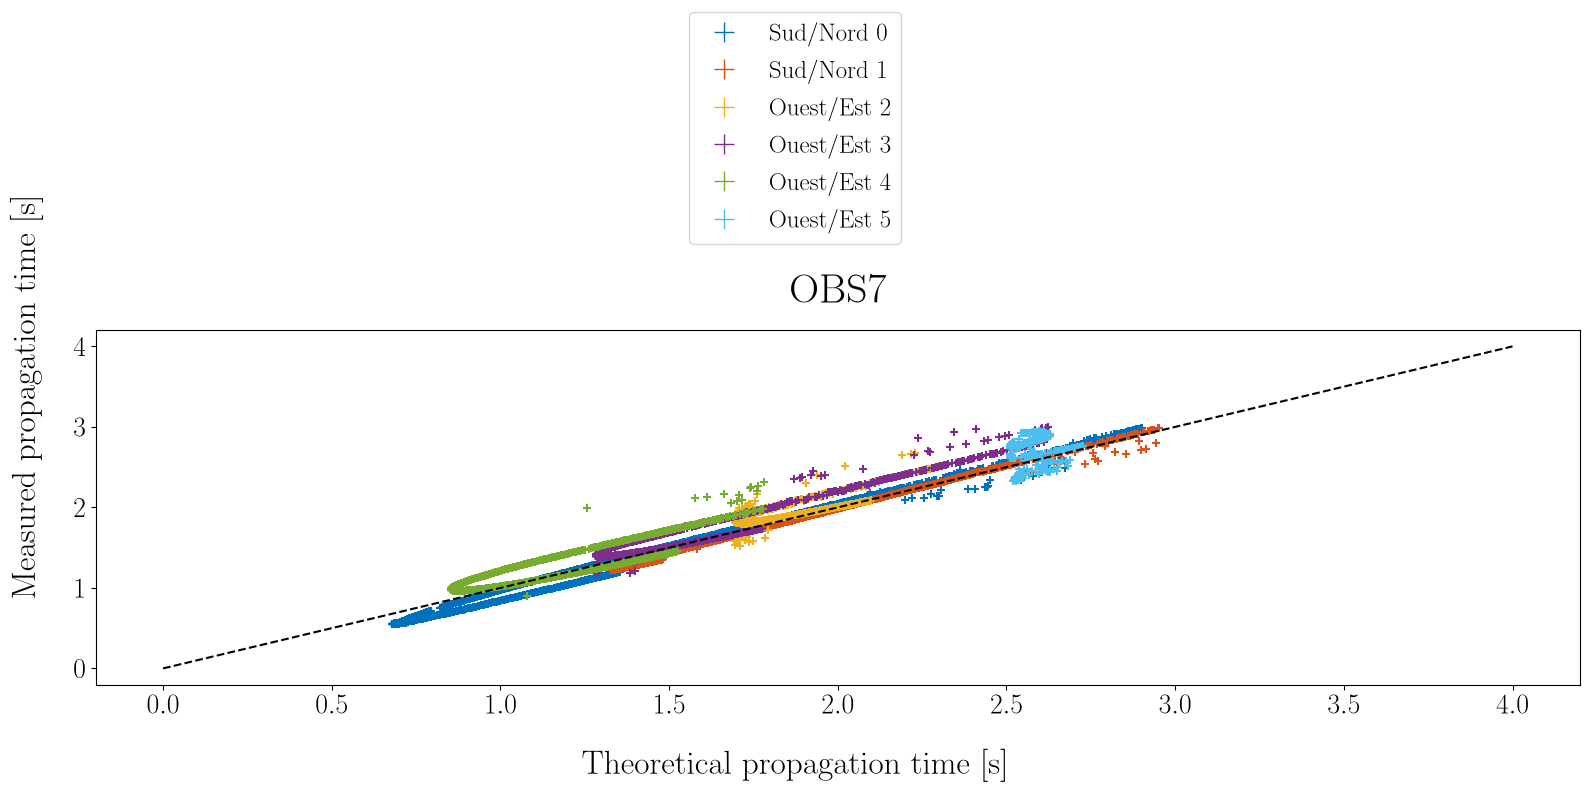

In [115]:
fig, axs = plt.subplots(nrows=1, ncols=len(obs_ids), figsize=(16, 8), sharex=True, sharey=True)
axs = np.atleast_1d(axs)
j = 0
legend_handles = []
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    for i, rcv_id in enumerate(obs_ids):
        ds_pos_section_rcv = ds_pos_section.sel(rcv_id=rcv_id)
        axs[i].scatter(
            ds_pos_section_rcv.tps_propagation_s,
            ds_pos_section_rcv.tps_propagation_measured_s,
            color=color(j),
            marker="+",
            s=30,
        )

    legend_handles.append(
        Line2D(
            [0],
            [0],
            linestyle="None",
            marker="+",
            markersize=15,
            label=f"{ds_pos_section.section_orientation} {ds_pos_section.section_id}",
            color=color(j),
        ),
    )
    j += 1

# Add ref diagonal
for i, rcv_id in enumerate(obs_ids):
    axs[i].plot(
        [0, 4],
        [0, 4],
        color="k",
        linestyle="--",
    )
    axs[i].set_title(rcv_id.upper())

fig.legend(
    handles=legend_handles,
    loc="outside upper center",
    ncols=len(legend_handles)//5,
    fontsize=18,
)
fig.supxlabel("Theoretical propagation time [s]")
fig.supylabel("Measured propagation time [s]")

Le décalage observé entre temps de propagation théorique et temps de propagation mesuré évolue en fonction de la position de la source pour l'OBS 7. 

Cette figure renforce l'hypothèse d'une position erronée pour l'OBS 7. 

## Application moindres carrés 

In [116]:
from publication.publication_figure import PubFigure, color
from misc import equivalent_celerity, calc_wls, draw_ellipse

# ======================================================================================================================
# LMS
# ======================================================================================================================
def f(X, X_s):
    """
    Parameters
    ----------
    X : array
        [y, x, z] position of the hydrophone to estimate in the local reference frame
    X_s : 2D array
        [y, x, z] positions of the source

    """
    x, y, z = X
    x_s, y_s, z_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]
    d2 = (x - x_s) ** 2 + (y - y_s) ** 2 + (z - z_s) ** 2

    return d2


def jac(X, X_s):
    """
    Parameters
    ----------
    X : array
        [y, x, z] position of the hydrophone to estimate in the local reference frame
    X_s : 2D array
        [y, x, z] positions of the source
    """
    x, y, z = X
    x_s, y_s, z_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]

    df_dx = 2 * (x - x_s)
    df_dy = 2 * (y - y_s)
    df_dz = 2 * (z - z_s)
    J = np.array([df_dx, df_dy, df_dz]).T

    return J



In [117]:
def inverse_obs_loc(
    meas_prop_time, e_pos, n_pos, u_pos, e_obs, n_obs, u_obs, c0=1508, plot=True, verbose=False
):

    # Grandeur signante -> y = d**2 = (t_prop * c)**2
    y = (meas_prop_time * c0) ** 2

    # Position a priori
    X_0 = np.array([e_obs, n_obs, u_obs])   # (3,)

    # Position succesives de la source
    X_s = np.stack((e_pos, n_pos, u_pos)).T # (npos, 3)

    # Remove nans
    idx_nan = np.isnan(y * X_s[:, 0] * X_s[:, 1] * X_s[:, 2])
    y = y[~idx_nan]
    X_s = X_s[~idx_nan, :]

    # Weighting matrix
    # W = np.diag(1 / y_var)
    W = np.eye(len(y))  # Initialisation avec la matrice identité

    # Apply LMS
    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = calc_wls(
        Y=y, t=X_s, X_0=X_0, W=W, fct=f, jac=jac, tol=1e-6, verbose=False
    )
    # print(f"True position : x = {e}, y = {n}, z = {u}")
    if verbose:
        print(f"Estimated position : x = {X_hat[0]}, y = {X_hat[1]}, z = {X_hat[2]}")
        print(f"Residuals : {dY_hat}")
        print(f"Final cost : {cost_hat}")
        print(SigmaXhat)

    if plot:

        plt.figure()
        # Origine du repère locale
        plt.scatter(
            0,
            0,
            s=300,
            c="deeppink",
            marker="+",
            # edgecolors="black",
            linewidths=3,
            zorder=10,
            label="ENU frame origin",
        )

        # Position a priori
        plt.scatter(
            X_0[0],
            X_0[1],
            marker="*",
            s=100,
            color="b",
            label=r"$X_0$",
            zorder=2,
        )

        # Position estimée
        plt.scatter(
            X_hat[0],
            X_hat[1],
            marker="*",
            s=100,
            color="r",
            label=r"$\hat{X}$",
            zorder=2,
        )

        # Ellipse de confiance
        alpha = 0.95
        # nombre d'observations
        nobs = y.shape[0]
        # nombre de paramètres inconnus
        nparams = 2
        ddl = nobs - nparams
        draw_ellipse(
            X=X_hat[0:2],
            SigmaX=SigmaXhat[0:2, 0:2],
            ddl=ddl,
            alpha=alpha,
            title="",
            color="k",
            fac=1,
        )

        ax = plt.gca()
        ax.axis("equal")
        plt.xlabel("E [m]")
        plt.ylabel("N [m]")
        # plt.title(f"OBS{obs_id}")

    return X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat

In [118]:
# Build vectors
meas_prop_time = []
e_pos = []
n_pos = []
u_pos = []

for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset().sel(rcv_id=obs_ids)
    meas_prop_time.append(ds_pos_section.tps_propagation_measured_s.values)
    e_pos.append(ds_pos_section.tir_src_e.values)
    n_pos.append(ds_pos_section.tir_src_n.values)
    u_pos.append(ds_pos_section.tir_src_u.values)

meas_prop_time = np.hstack(meas_prop_time)
e_pos = np.hstack(e_pos)
n_pos = np.hstack(n_pos)
u_pos = np.hstack(u_pos)
e_obs = ds_pos_section.rcv_e.values
n_obs = ds_pos_section.rcv_n.values
u_obs = ds_pos_section.rcv_u.values

In [119]:
meas_prop_time.shape

(1, 3119)

[[  31.95617755    7.50982145   45.8304791 ]
 [   7.50982145   31.68429056  163.41159114]
 [  45.8304791   163.41159114 1025.8605498 ]]
sigma_x = 32.0 m, sigma_y = 31.7 m, sigma_z = 1025.9 m


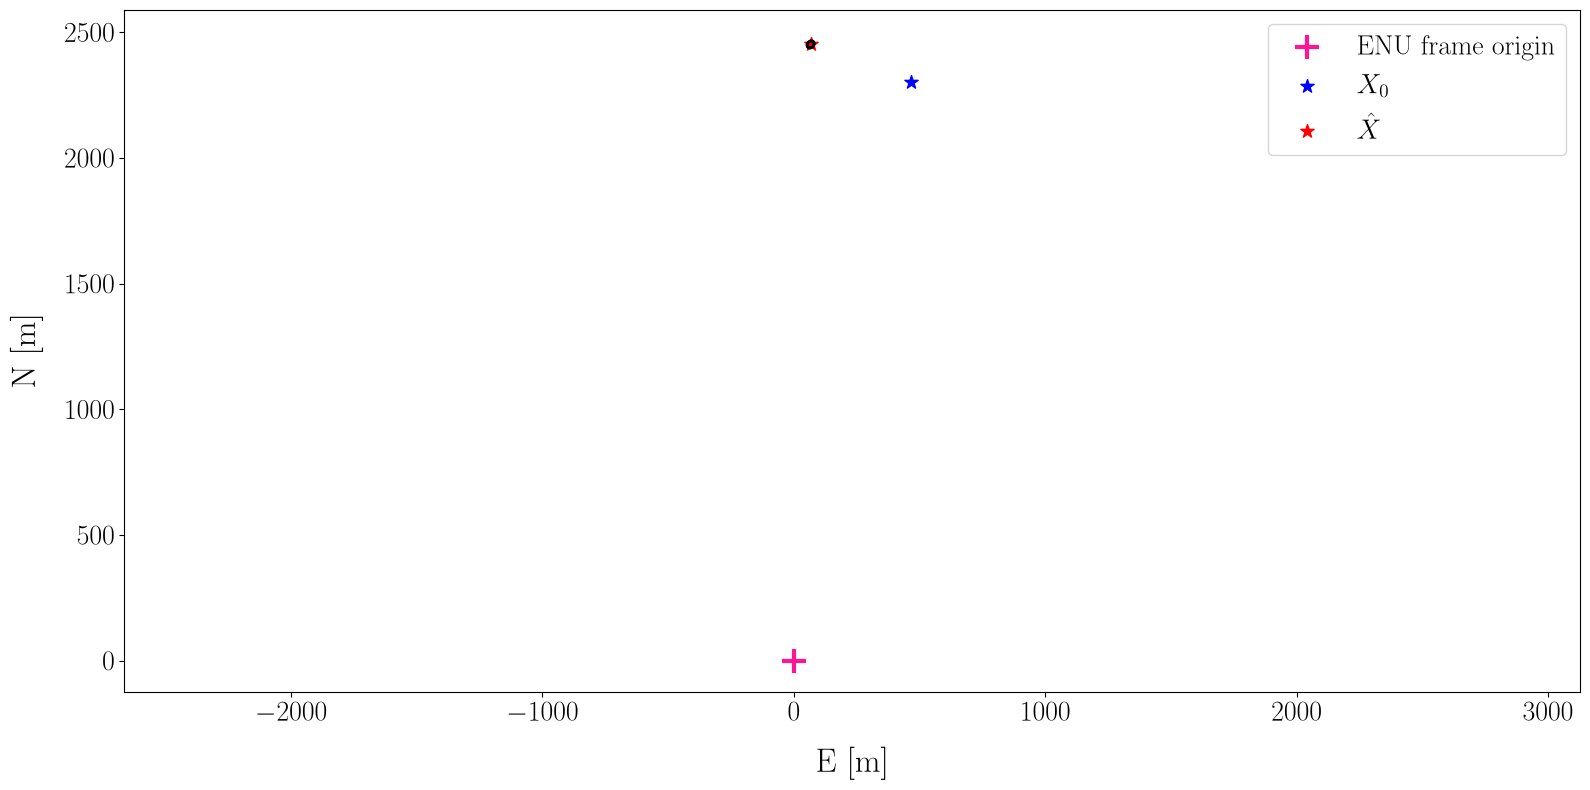

In [128]:
for i, rcv_id in enumerate(obs_ids):
    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc(
        meas_prop_time[i, ],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i],
        c0=1508,
        plot=True,
        verbose=False,
    )

    print(SigmaXhat)
    print(f"sigma_x = {SigmaXhat[0, 0]:.1f} m, sigma_y = {SigmaXhat[1, 1]:.1f} m, sigma_z = {SigmaXhat[2, 2]:.1f} m")

Très forte incertitude sur la composante z. Ce résultat est attendue : toutes les émissisions sont sur le même plan. 

Afin d'éviter ce problème, on contraint la coordonnée z. 

### Cas 2D

In [131]:
import numpy as np


def f2D(X, X_s, u_fixed):
    """
    X       : array [e, n], position horizontale de l'OBS à estimer
    X_s     : 2D array (npos, 3), positions [e, n, u] de la source
    u_fixed : float, coordonnée u de l'OBS, fixée (non estimée)
    """
    e, n = X
    e_s, n_s, u_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]
    return (e - e_s) ** 2 + (n - n_s) ** 2 + (u_fixed - u_s) ** 2


def jac2D(X, X_s, u_fixed):
    """Jacobienne (npos, 2) : dérivées par rapport à e et n uniquement."""
    e, n = X
    e_s, n_s = X_s[:, 0], X_s[:, 1]
    df_de = 2 * (e - e_s)
    df_dn = 2 * (n - n_s)
    return np.array([df_de, df_dn]).T


def inverse_obs_loc2D(
    meas_prop_time,
    e_pos,
    n_pos,
    u_pos,
    e_obs,
    n_obs,
    u_obs,
    c0=1508,
    plot=True,
    verbose=False,
    ax=None,
):

    y = (meas_prop_time * c0) ** 2

    # A priori : seulement e, n
    X_0 = np.array([e_obs, n_obs])  # (2,)
    X_s = np.stack((e_pos, n_pos, u_pos)).T  # (npos, 3)

    idx_nan = np.isnan(y * X_s[:, 0] * X_s[:, 1] * X_s[:, 2])
    y = y[~idx_nan]
    X_s = X_s[~idx_nan, :]

    W = np.eye(len(y))

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = calc_wls(
        Y=y,
        t=X_s,
        X_0=X_0,
        W=W,
        fct=f2D,
        jac=jac2D,
        f_kwargs={"u_fixed": u_obs},
        jac_kwargs={"u_fixed": u_obs},
        tol=1e-6,
        verbose=False,
    )

    e_hat, n_hat = X_hat

    # print(f"True position : x = {e}, y = {n}, z = {u}")
    if verbose:
        print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
        print(f"Residuals : {dY_hat}")
        print(f"Final cost : {cost_hat}")
        print(SigmaXhat)

    if plot:
        if ax is None:
            fig, ax = plt.subplots()
        # Origine du repère locale
        ax.scatter(
            0,
            0,
            s=300,
            c="deeppink",
            marker="+",
            # edgecolors="black",
            linewidths=3,
            zorder=10,
            label="ENU frame origin",
        )

        # Position a priori
        ax.scatter(
            X_0[0],
            X_0[1],
            marker="*",
            s=100,
            color="b",
            label=r"$X_0$",
            zorder=2,
        )

        # Position estimée
        ax.scatter(
            X_hat[0],
            X_hat[1],
            marker="*",
            s=100,
            color="r",
            label=r"$\hat{X}$",
            zorder=2,
        )

        # Ellipse de confiance
        alpha = 0.95
        # nombre d'observations
        nobs = y.shape[0]
        # nombre de paramètres inconnus
        nparams = 2
        ddl = nobs - nparams
        draw_ellipse(
            X=X_hat[0:2],
            SigmaX=SigmaXhat[0:2, 0:2],
            ddl=ddl,
            alpha=alpha,
            title="",
            color="k",
            fac=1,
        )

        ax = plt.gca()
        ax.axis("equal")
        plt.xlabel("E [m]")
        plt.ylabel("N [m]")
        # plt.title(f"OBS{obs_id}")

    return X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat

In [137]:
correction_u = [0, 0, 0 , 0]
for i, rcv_id in enumerate(obs_ids):

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
        meas_prop_time[i, :],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i] + correction_u[i],
        c0=1508,
        plot=False,
        verbose=False,
        ax=None,
    )

    # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
    # print(f"Residuals : {dY_hat}")
    print(f"Final cost : {cost_hat}")
    print(SigmaXhat)
    print(f"sigma_x = {SigmaXhat[0, 0]:.1f} m, sigma_y = {SigmaXhat[1, 1]:.1f} m")
    
    pos_err = np.sqrt((X_hat[0] - e_obs[i]) ** 2 + (X_hat[1] - n_obs[i]) ** 2)
    print(f"Erreur de positionnement {rcv_id.upper()} : {pos_err} m")

Final cost : 1490538942877859.2
[[30.28596255  0.08698725]
 [ 0.08698725  5.59851111]]
sigma_x = 30.3 m, sigma_y = 5.6 m
Erreur de positionnement OBS7 : 429.61246527997235 m


L'incertitude est plus importante que dans le cas de la portion 2, cependant le coût final est plus faible :

* Inversion avec la portion 2 : 1873279649208419.0
* Inversion avec la portion 3 : 1490538942877859.2

ATTENTION : le coût n'est pas comparable car l'origine du repère n'est pas la même et l'erreur est donnée sur le paramètre inversé à savoir ici $d² = (t \times c)²$. La fonction $x \mapsto x²$ n'étant pas linéaire les résultats ne sont pas directement comparable en terme de cout final. 

Text(0, 0.5, 'N [m]')

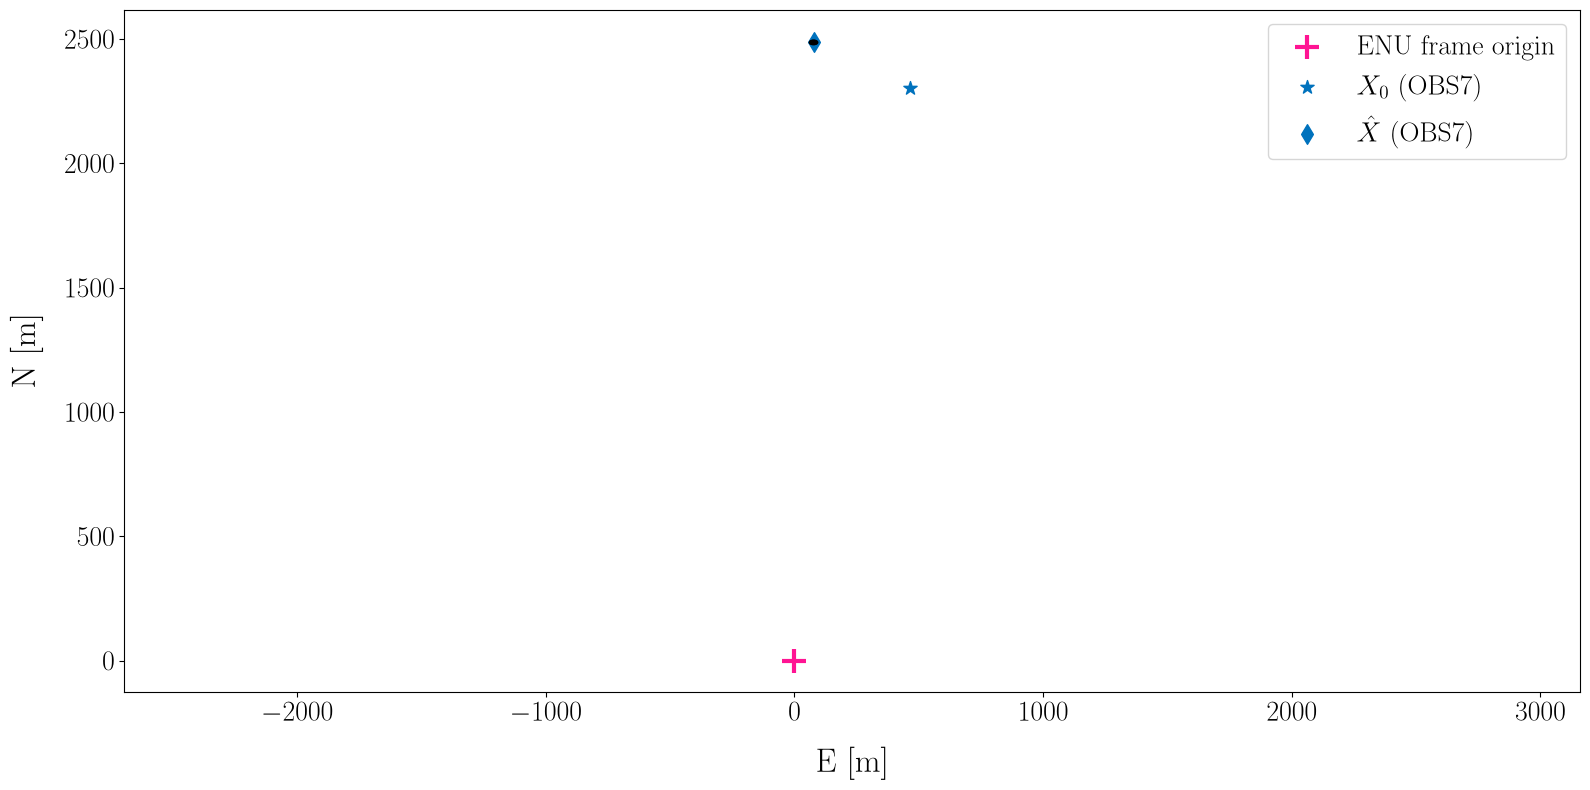

In [133]:
fig, ax = plt.subplots()

# Origine du repère locale
ax.scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)

rcv_corrected_pos = {}
for i, rcv_id in enumerate(obs_ids):

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
        meas_prop_time[i,:],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i],
        c0=1508,
        plot=False,
        verbose=False,
        ax=None,
    )

    rcv_corrected_pos[rcv_id] = {"e": X_hat[0], "n": X_hat[1], "u": u_obs[i]}


    # Position a priori
    ax.scatter(
        e_obs[i],
        n_obs[i],
        marker="*",
        s=100,
        color=color(i),
        label=r"$X_0$" + f" ({rcv_id.upper()})",
        zorder=2,
    )

    # Position estimée
    ax.scatter(
        X_hat[0],
        X_hat[1],
        marker="d",
        s=100,
        color=color(i),
        label=r"$\hat{X}$" + f" ({rcv_id.upper()})",
        zorder=2,
    )

    # Ellipse de confiance
    alpha = 0.95
    # nombre d'observations
    nobs = meas_prop_time[i, :].shape[0]
    # nombre de paramètres inconnus
    nparams = 2
    ddl = nobs - nparams
    draw_ellipse(
        X=X_hat[0:2],
        SigmaX=SigmaXhat[0:2, 0:2],
        ddl=ddl,
        alpha=alpha,
        title="",
        color="k",
        fac=1,
    )

ax.axis("equal")
plt.xlabel("E [m]")
plt.ylabel("N [m]")
# plt.title(f"OBS{obs_id}")

#### Impact de l'immersion a priori 

In [134]:
correction_u = np.linspace(-50, +50, 100)
cost_hat_u = []
for i, rcv_id in enumerate(obs_ids):

    cost_hat_u_ = []
    for i_corr, corr_u in enumerate(correction_u):

        X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
            meas_prop_time[i, :],
            e_pos,
            n_pos,
            u_pos,
            e_obs[i],
            n_obs[i],
            u_obs[i] + corr_u,
            c0=1508,
            plot=False,
            verbose=False,
            ax=None,
        )

        # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
        # print(f"Residuals : {dY_hat}")
        # print(f"Final cost : {cost_hat}")
        cost_hat_u_.append(cost_hat)

    cost_hat_u.append(cost_hat_u_)
cost_hat_u = np.array(cost_hat_u)

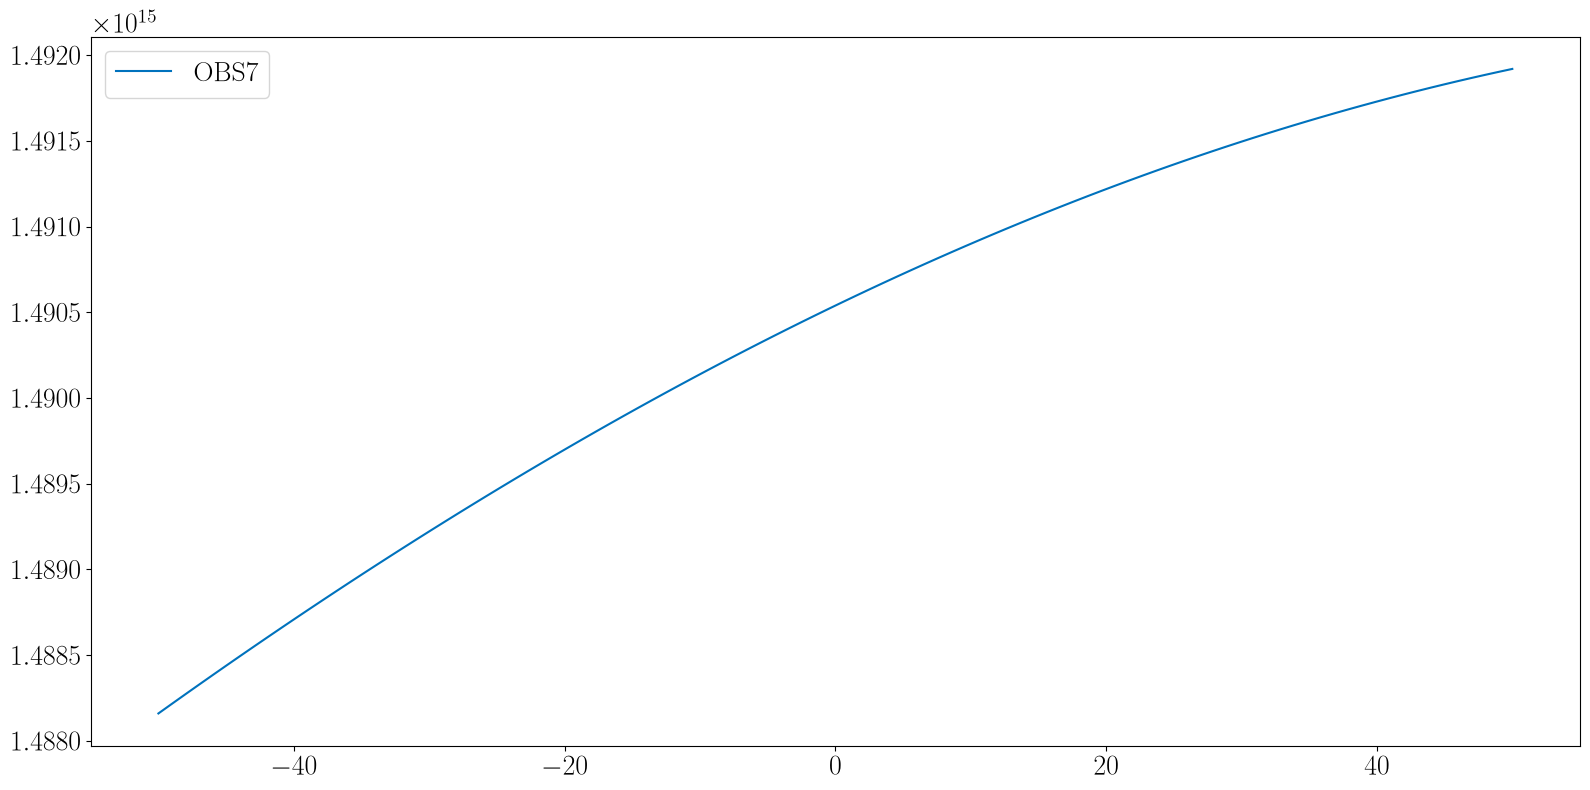

In [135]:
fig, axs = plt.subplots(len(obs_ids), 1, figsize=(16, 8))
axs = np.atleast_1d(axs)
for i, rcv_id in enumerate(obs_ids):
    axs[i].plot(
        correction_u,
        cost_hat_u[i, :],
        label=rcv_id.upper(),
        color=color(i),
    )
    # axs[i].plot(
    #     correction_u,
    #     (cost_hat_u[i, :] - np.min(cost_hat_u[i, :])) / (np.max(cost_hat_u[i, :]) - np.min(cost_hat_u[i, :])),
    #     label=rcv_id.upper(),
    #     color=color(i),
    # )
    axs[i].legend()

Pas de minimum et pas de variations significatives. Pas de correction à apporter à la coordonnée u.


#### Impact de la célérité a priori 

In [138]:
c0_ = np.linspace(1495, 1510, 100)
cost_hat_c0 = []
for i, rcv_id in enumerate(obs_ids):

    cost_hat_c0_ = []
    for i_corr, c0 in enumerate(c0_):

        X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
            meas_prop_time[i, :],
            e_pos,
            n_pos,
            u_pos,
            e_obs[i],
            n_obs[i],
            u_obs[i],
            c0=c0,
            plot=False,
            verbose=False,
            ax=None,
        )

        # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
        # print(f"Residuals : {dY_hat}")
        # print(f"Final cost : {cost_hat}")
        cost_hat_c0_.append(cost_hat)

    cost_hat_c0.append(cost_hat_c0_)
cost_hat_c0 = np.array(cost_hat_c0)

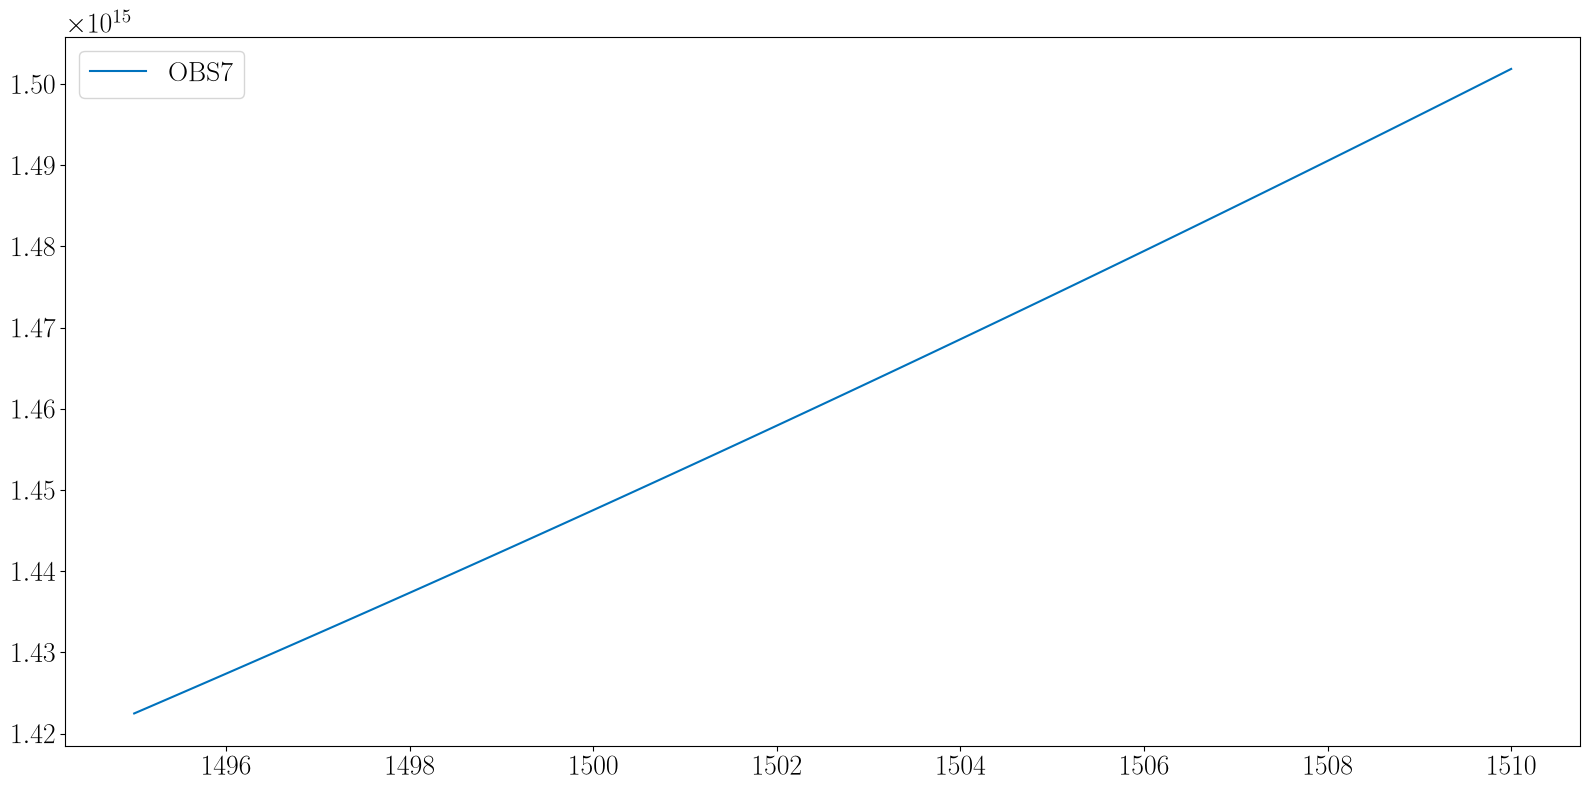

In [139]:
fig, axs = plt.subplots(len(obs_ids), 1, figsize=(16, 8))
axs = np.atleast_1d(axs)
for i, rcv_id in enumerate(obs_ids):
    axs[i].plot(
        c0_,
        cost_hat_c0[i, :],
        label=rcv_id.upper(),
        color=color(i),
    )
    # axs[i].plot(
    #     correction_u,
    #     (cost_hat_u[i, :] - np.min(cost_hat_u[i, :])) / (np.max(cost_hat_u[i, :]) - np.min(cost_hat_u[i, :])),
    #     label=rcv_id.upper(),
    #     color=color(i),
    # )
    axs[i].legend()

Pas de minimum et pas de variations significatives.

Est ce que cela a vraiment du sens de regarder les variations de coût total de la solution ? Peux être mieux de regarder $\sigma_x$, $\sigma_y$ ? 


# Temps d'arrivée après correction 

In [140]:
portion_corr = portion.copy()

In [141]:
from source.utils.utils_geo import enu_to_ecef, ecef_to_geodetic

In [142]:
# Compute corrected receiver positions 
rcv_lon_corr = []
rcv_lat_corr = []

name = list(portion_corr.position.children.keys())[0]
ds_pos_section = portion.position[name].to_dataset()
for rcv_id in ds_pos_section.rcv_id.values:

    if rcv_id in obs_ids:
        # Extract ENU corrected pos 
        pos_rcv_e = rcv_corrected_pos[rcv_id]["e"]
        pos_rcv_n = rcv_corrected_pos[rcv_id]["n"]
        pos_rcv_u = rcv_corrected_pos[rcv_id]["u"]
        # Convert ENU to ECEF
        x_rcv, y_rcv, z_rcv = enu_to_ecef(
            pos_rcv_e,
            pos_rcv_n,
            pos_rcv_u,
            lat0=np.deg2rad(local_frame_origin["lat"]),
            lon0=np.deg2rad(local_frame_origin["lon"]),
            h0=local_frame_origin["h"],
        )
        # Convert ECEF to WGS84
        lat_rcv, lon_rcv, _ = ecef_to_geodetic(x_rcv, y_rcv, z_rcv)
        lat_rcv = np.rad2deg(lat_rcv[0])
        lon_rcv = np.rad2deg(lon_rcv[0])
    else:
        lat_rcv = ds_pos_section.rcv_lat.sel(rcv_id=rcv_id).values
        lon_rcv = ds_pos_section.rcv_lon.sel(rcv_id=rcv_id).values

    # Store 
    rcv_lon_corr.append(lon_rcv)
    rcv_lat_corr.append(lat_rcv)

rcv_lon_corr = np.array(rcv_lon_corr)
rcv_lat_corr = np.array(rcv_lat_corr)

# Update tree
for name, node in portion_corr.position.children.items():
    ds_pos_section = node.to_dataset()

    # Update ds_pos_section
    ds_pos_section.update(
        {
            "rcv_lon": ("rcv_id", rcv_lon_corr),
            "rcv_lat": ("rcv_id", rcv_lat_corr), 
         }
    )
    # No need to update immersion as it is not changed (2D LMS estimation)

    # Update tree
    node.ds = ds_pos_section

In [152]:
ds_pos_section = portion.position[name].to_dataset()
ds_pos_section_corr = portion_corr.position[name].to_dataset()

print(f"Position correction :")
for rcv_id in obs_ids:
    print(
        f"{rcv_id.upper()} : {ds_pos_section.sel(rcv_id=rcv_id).rcv_lat.values, ds_pos_section.sel(rcv_id=rcv_id).rcv_lon.values} -> {ds_pos_section_corr.sel(rcv_id=rcv_id).rcv_lat.values, ds_pos_section_corr.sel(rcv_id=rcv_id).rcv_lon.values}"
    )


Position correction :
OBS7 : (array(43.0545), array(5.9695)) -> (array(43.05615849), array(5.96473614))


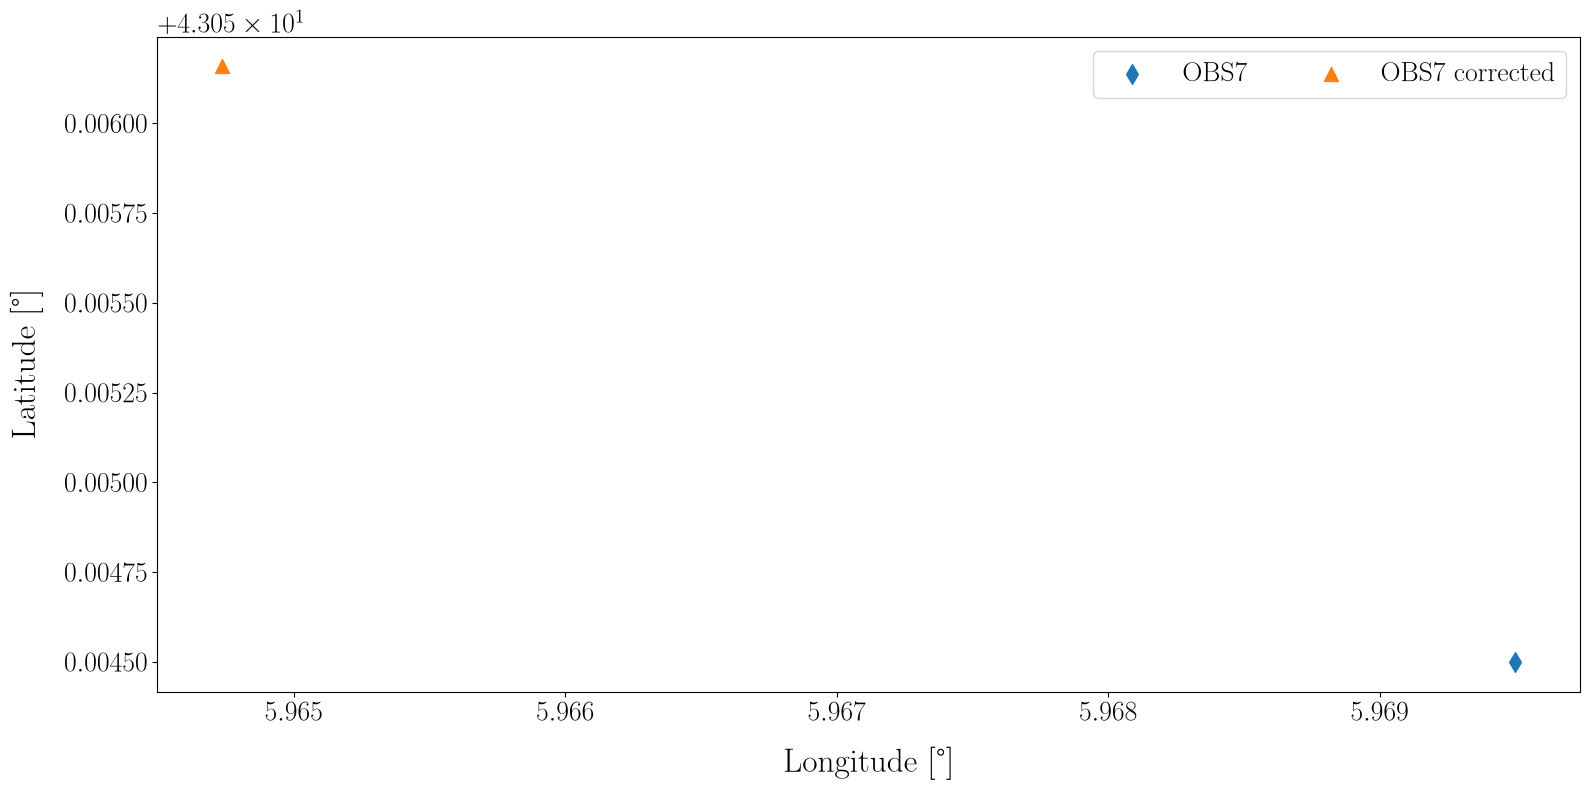

In [143]:
# Compare coords 
name = list(portion.position.children.keys())[0]
ds_pos_section = portion.position[name].to_dataset()
ds_pos_section_corr = portion_corr.position[name].to_dataset()
fig, ax = plt.subplots()

for rcv_id in obs_ids:
    # Original 
    rcv = ds_pos_section.sel(rcv_id=rcv_id)
    ax.scatter(rcv.rcv_lon, rcv.rcv_lat, marker="d", label=f"{rcv_id.upper()}", s=100)

    # Correction 
    rcv = ds_pos_section_corr.sel(rcv_id=rcv_id)
    ax.scatter(rcv.rcv_lon, rcv.rcv_lat, marker="^", label=f"{rcv_id.upper()} corrected", s=100)

ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")

_, labels = ax.get_legend_handles_labels()
ncols = min(len(labels), 4)
ax.legend(ncols=ncols)


In [144]:
c0 = 1508       # equivalent celerity 
for name, node in portion_corr.position.children.items():
    ds_pos_section = node.to_dataset()

    # Compute corrected geodetic distance between source and receiver
    ds_pos_section = compute_src_rcv_geodesic_dist(ds_pos_sections=[ds_pos_section])[0]

    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time
    tps_propagation_s = dpropa_direct / c0 

    # Update ds_pos_section with propagation time
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    # Update ds_pos_section with arrival datetime
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

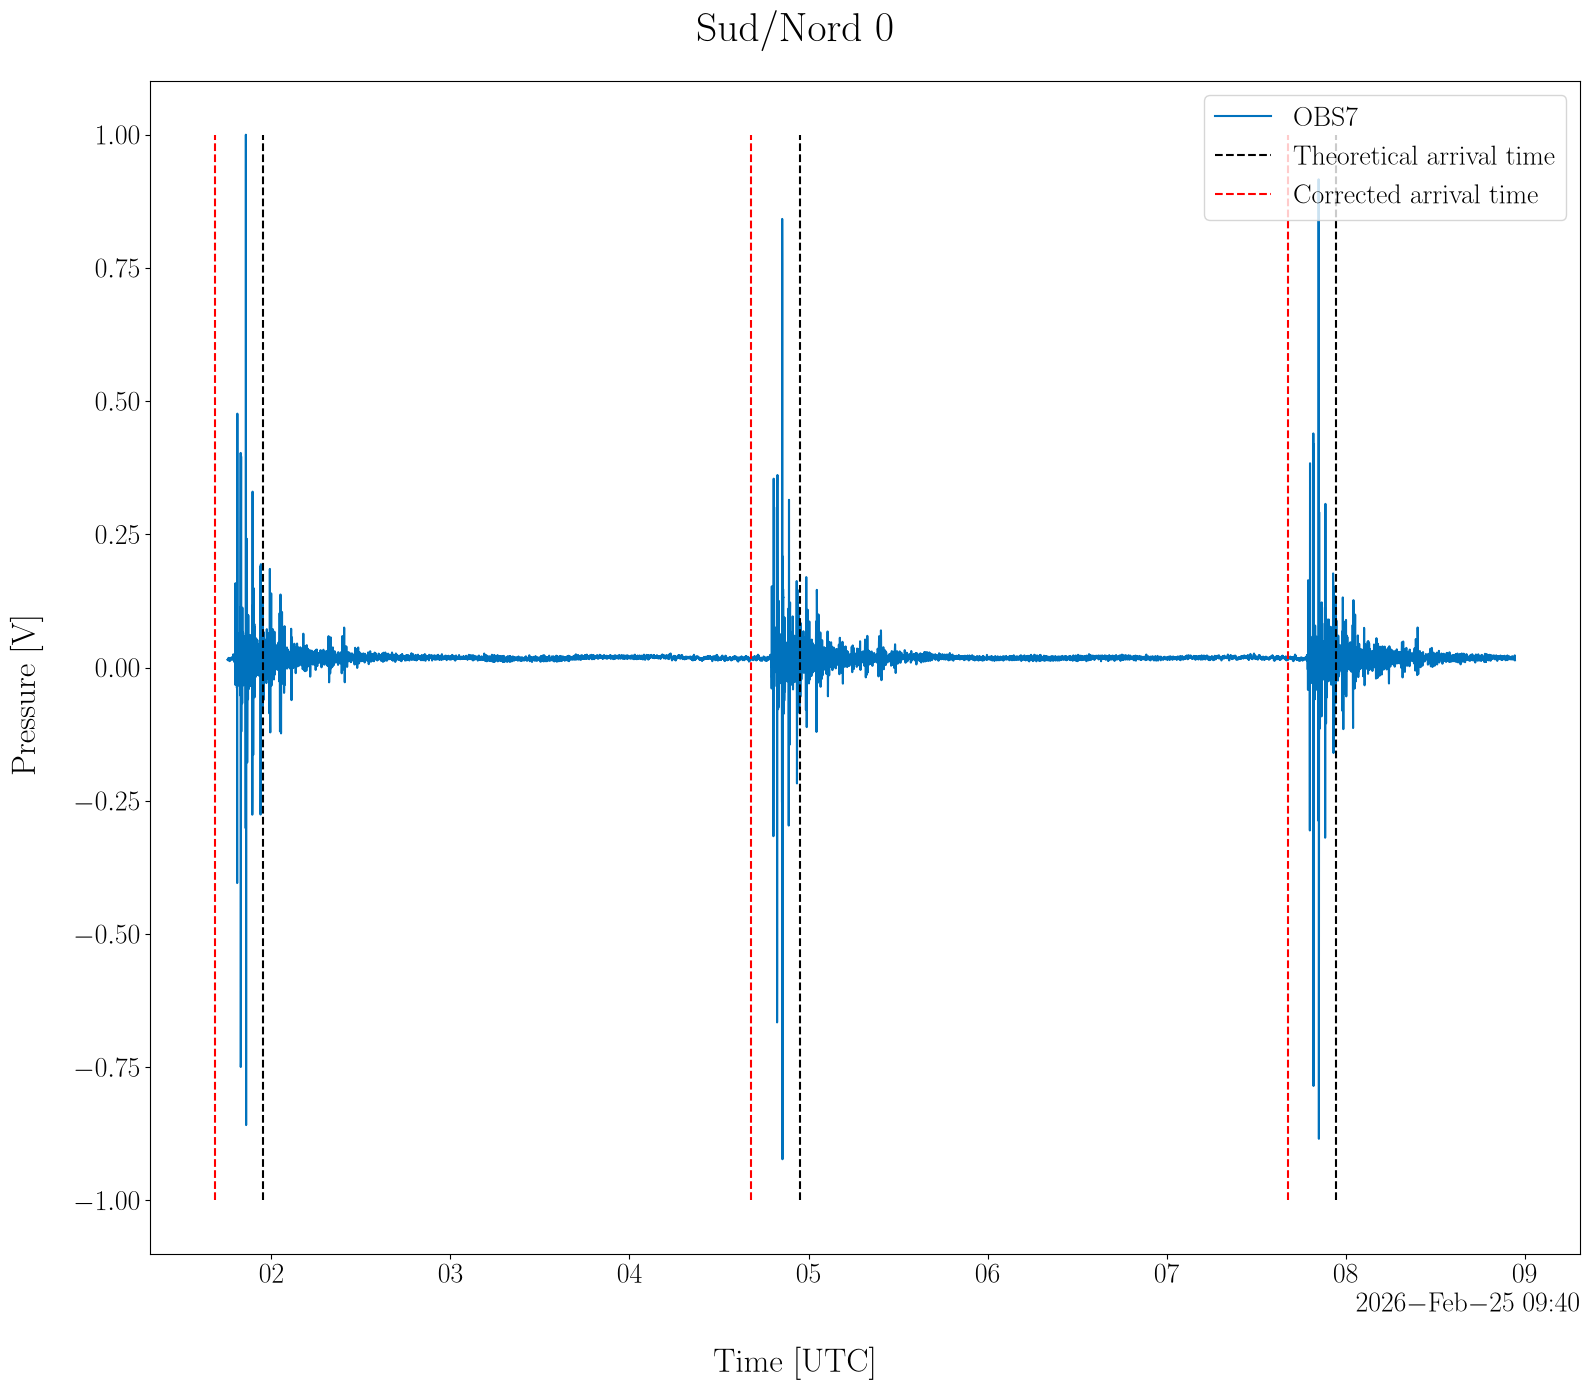

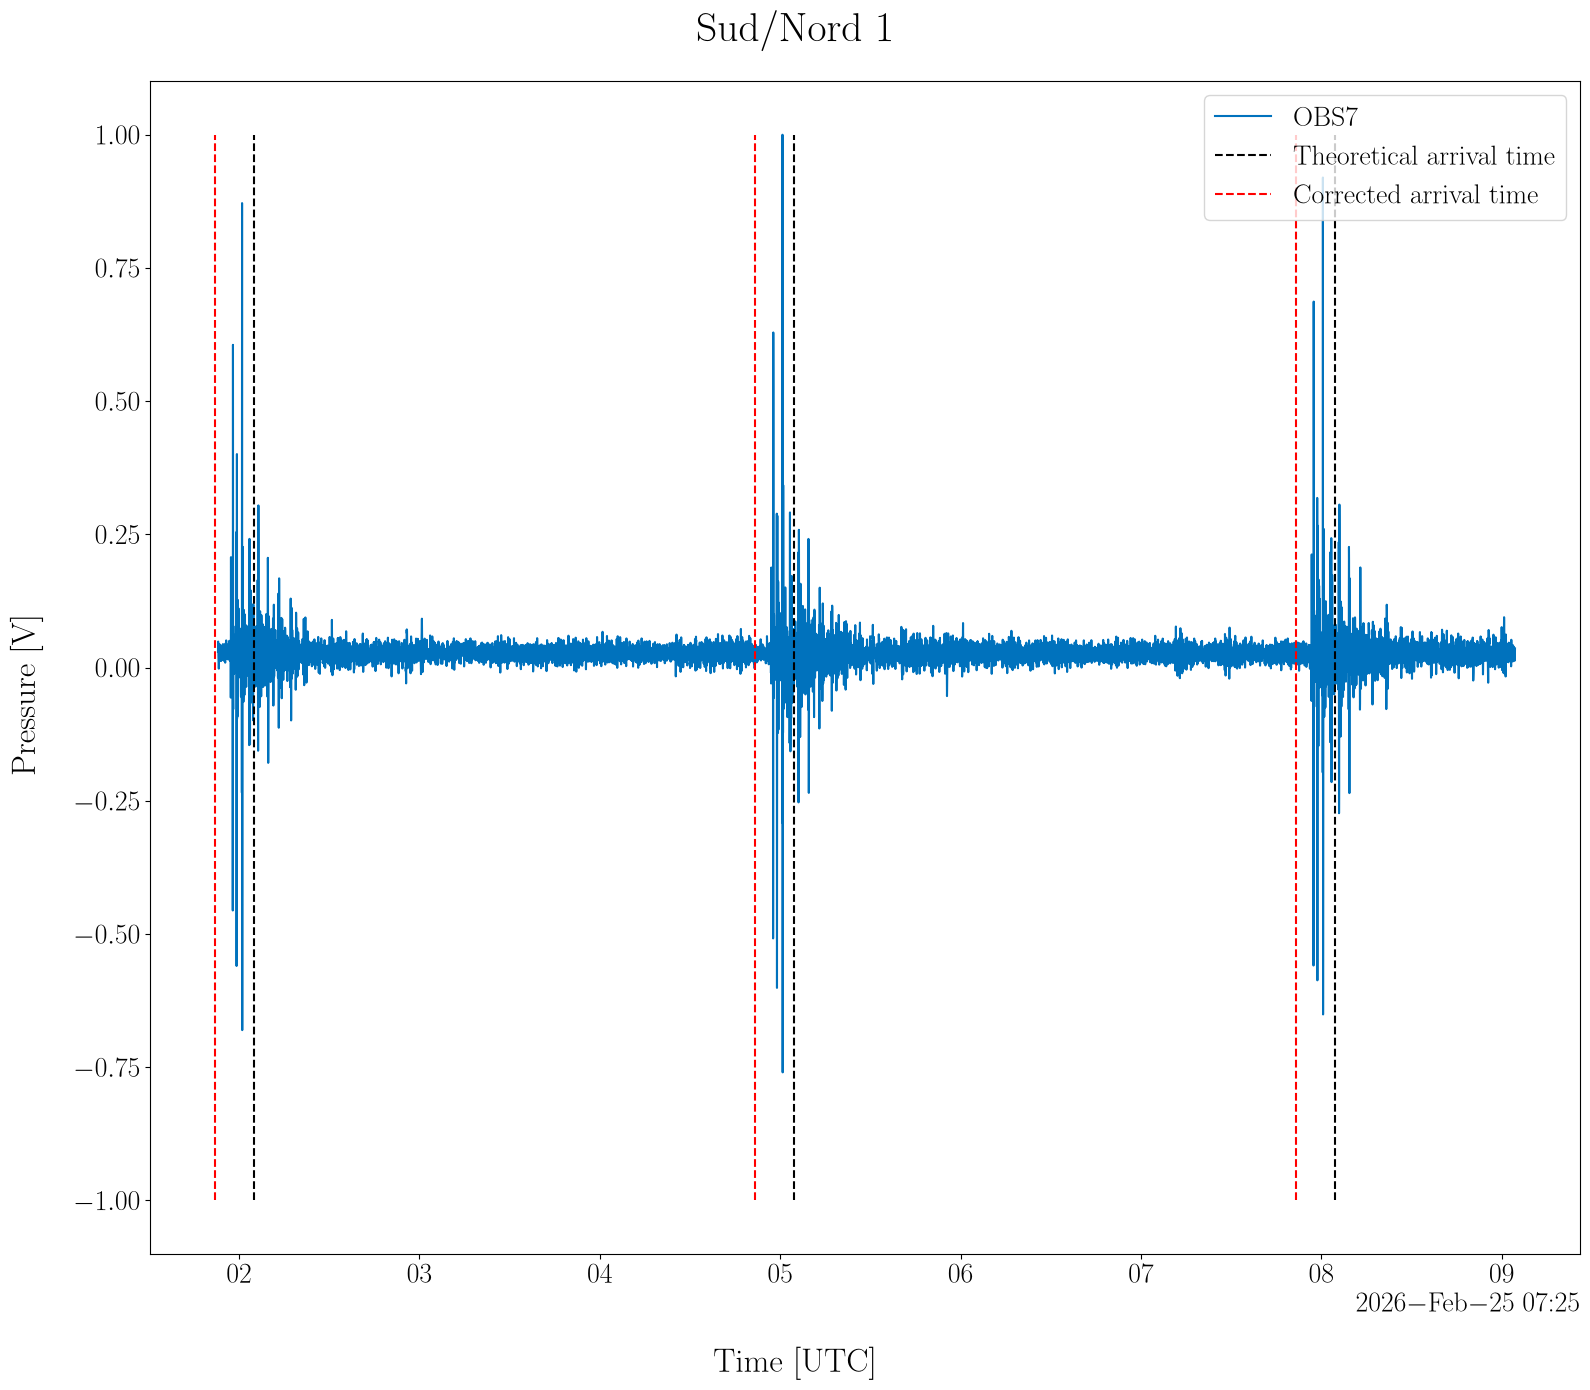

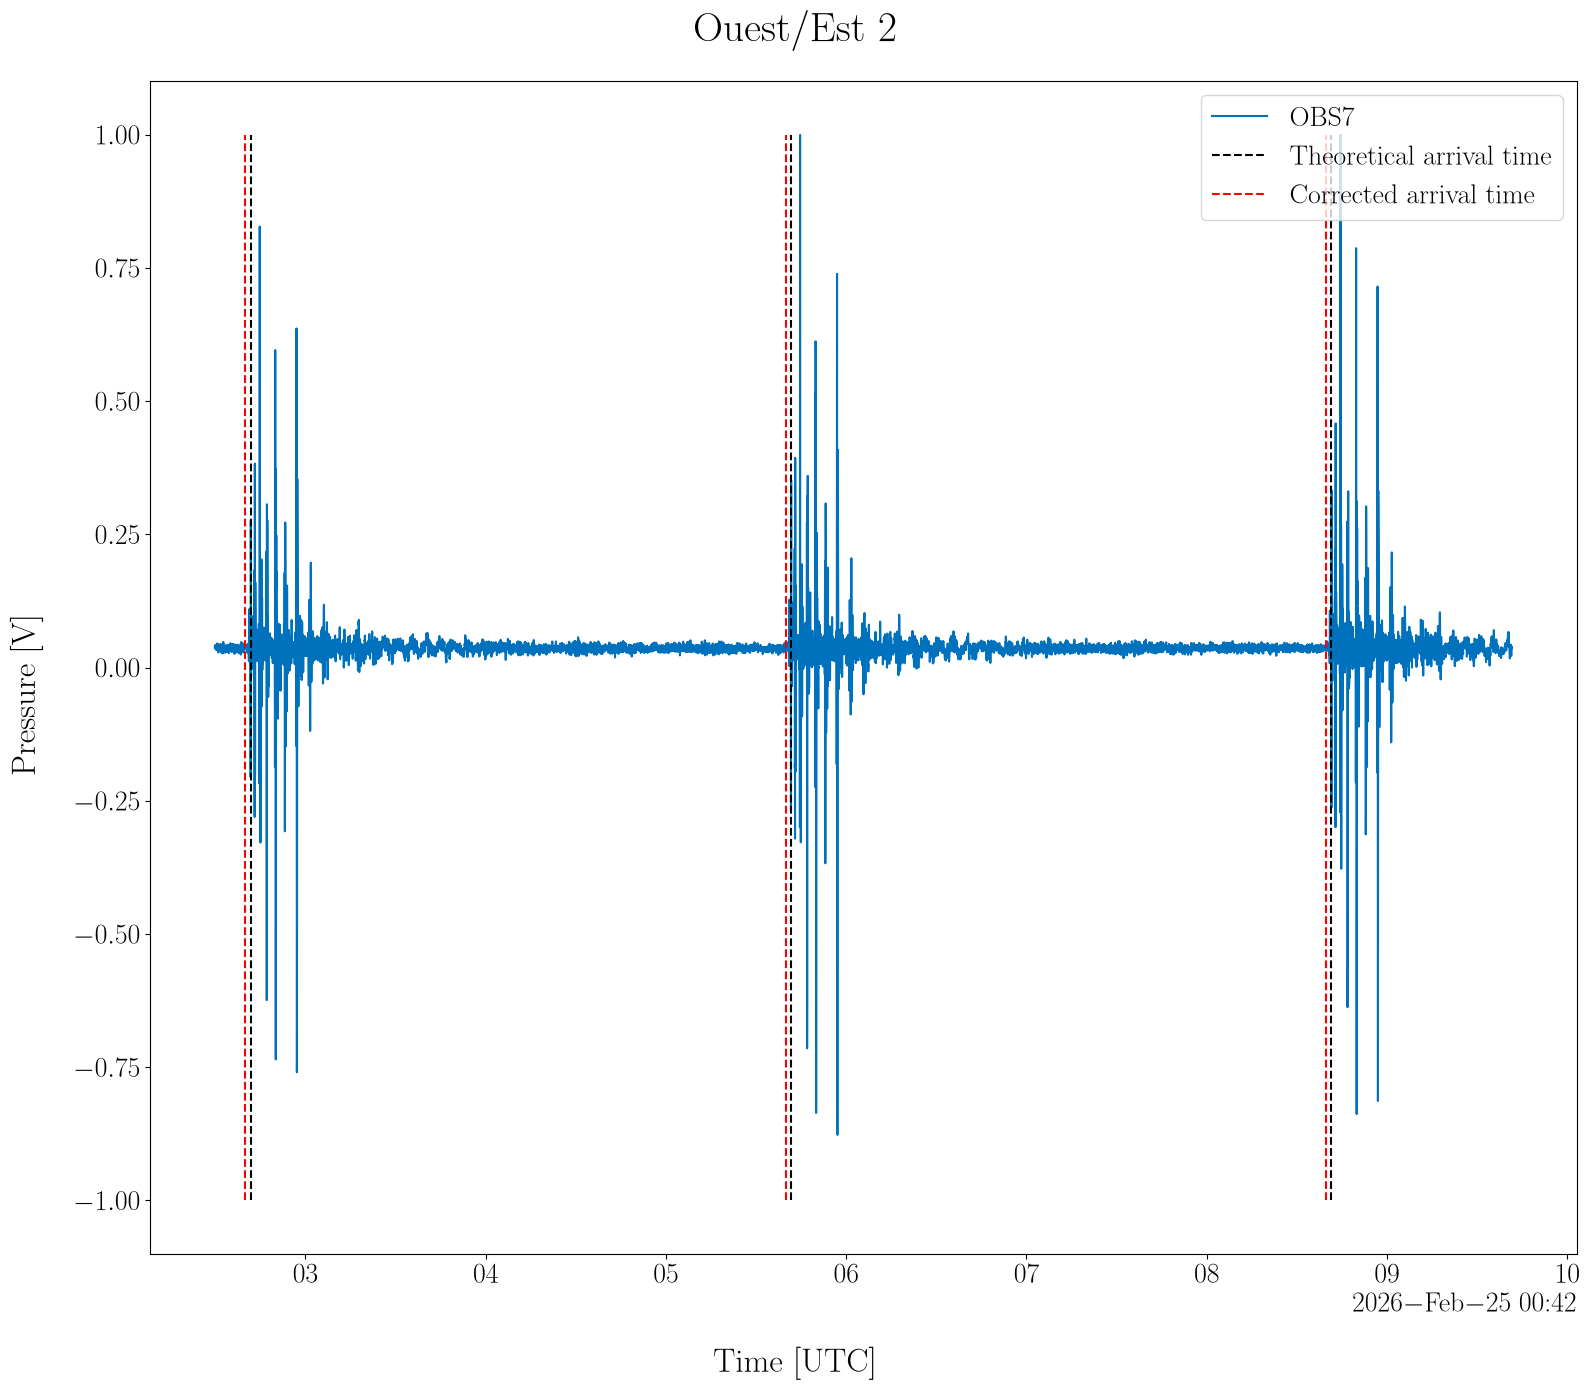

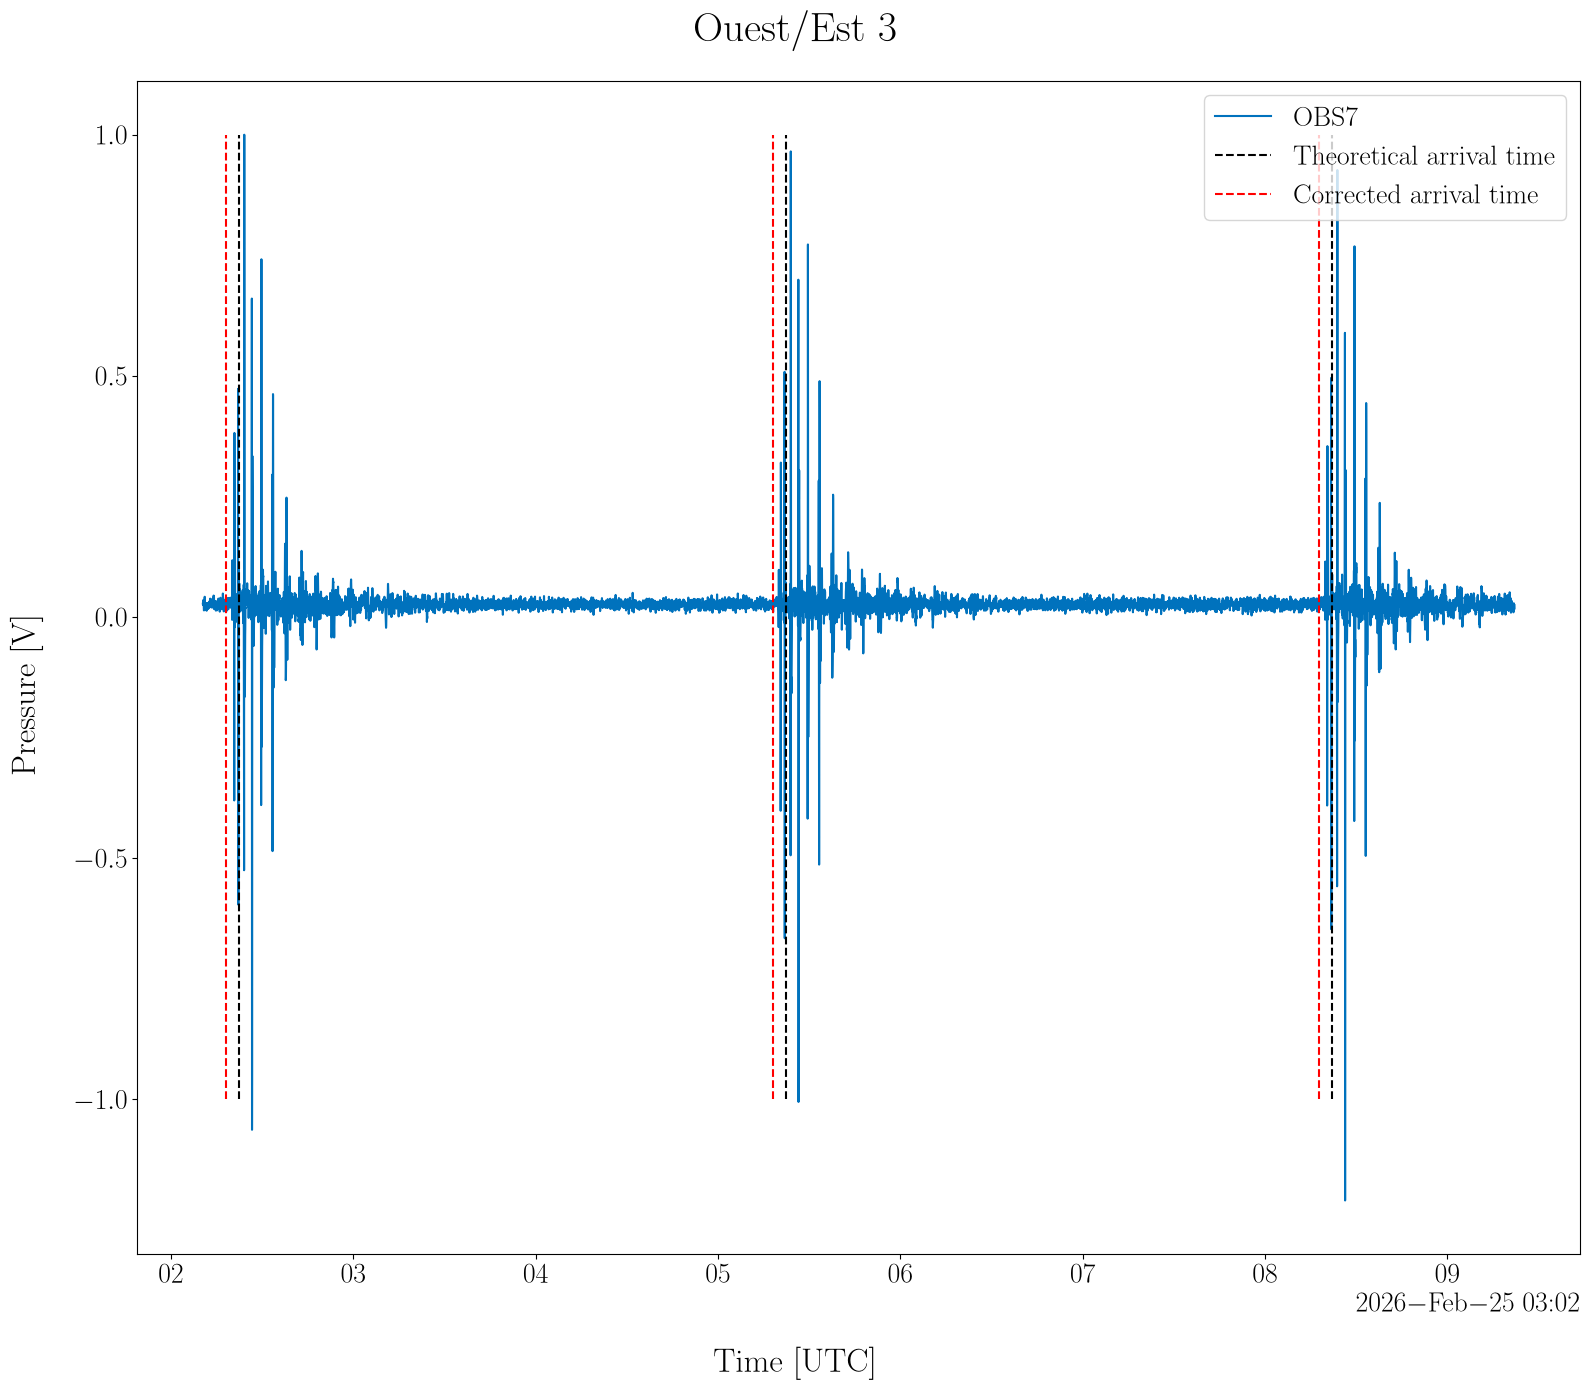

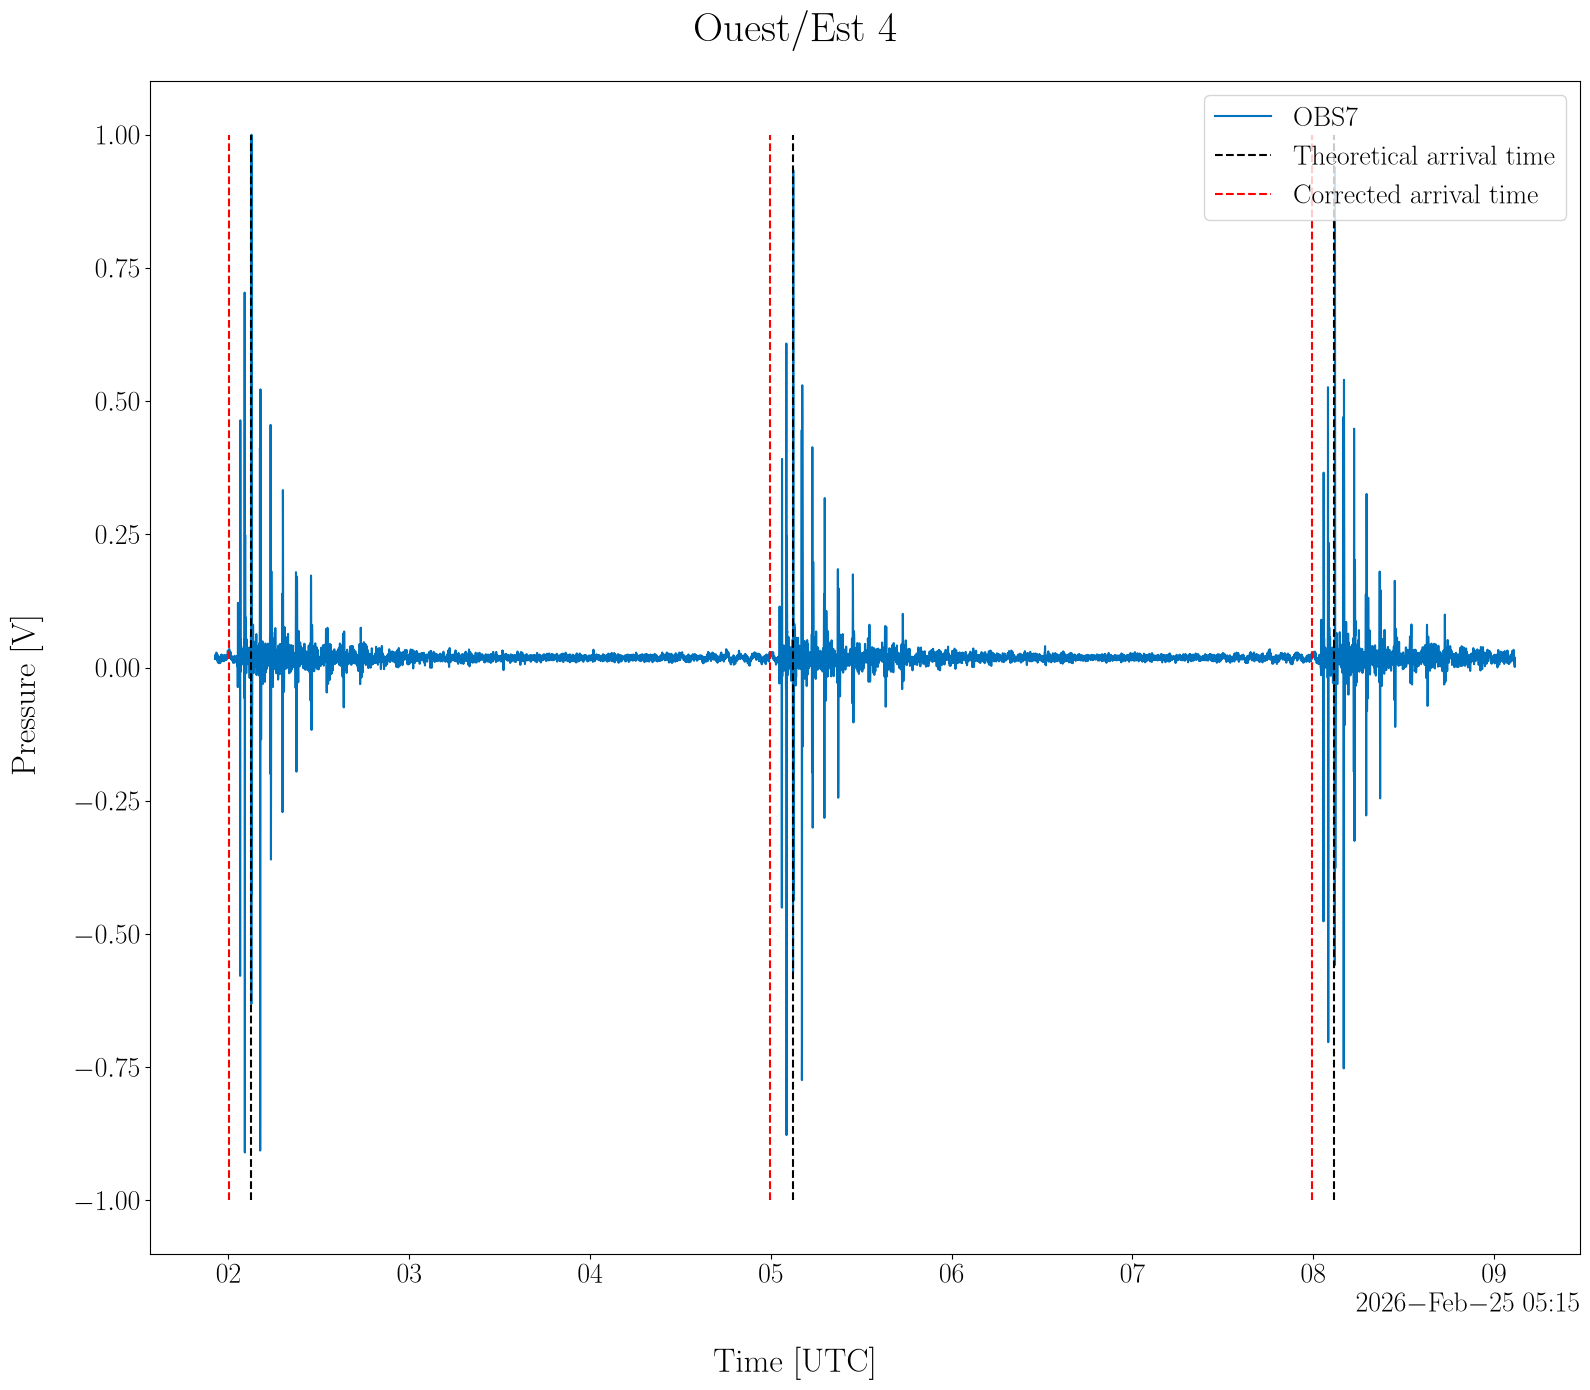

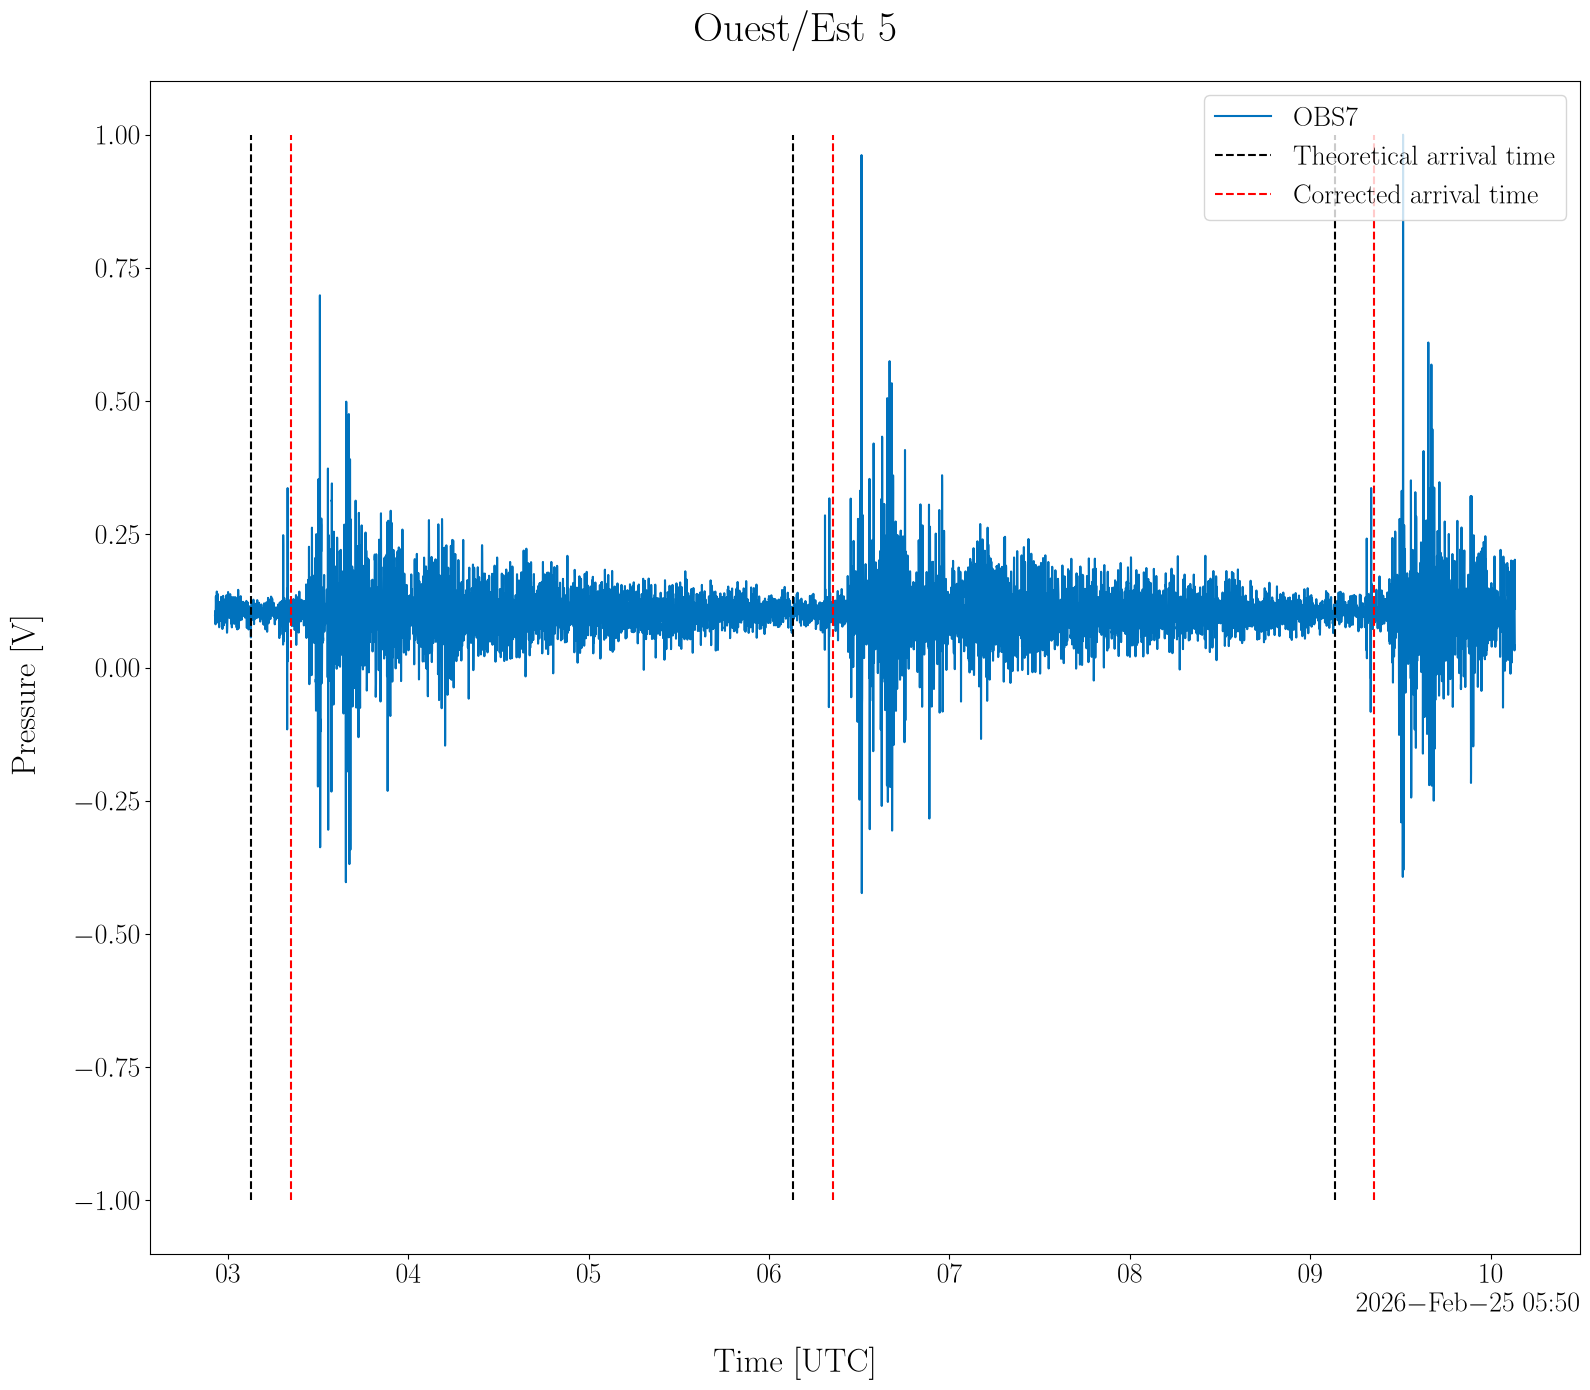

In [147]:
nb_tir = 3
offset1 = 200
offset2 = 1000

for name, node in portion.pressure.children.items():

    ds_pressure_section = node.to_dataset()  
    ds_pressure_section_corr = portion_corr.pressure[name].to_dataset()

    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))
    ds_pos_section_corr = portion_corr.position[name].to_dataset()
    tir_dt_corr = ds_pos_section_corr["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=len(obs_ids), ncols=1, figsize=(16, 14), sharex=False)        
    axs = np.atleast_1d(axs)
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        tir_dt_rcv_corr = tir_dt_corr.sel(rcv_id=rcv_id)

        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})

        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--", label="Theoretical arrival time")
        axs[i].vlines(x=tir_dt_rcv_corr, ymin=-1, ymax=1, color="r", linestyle="--", label="Corrected arrival time")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

Les performances semblent similaires à celles observées pour l'inversion à l'aide de la portion 2.